<a href="https://colab.research.google.com/github/noeliacualina/Procesamiento_digital_imagenes/blob/TrabajoPractico_2/TP2_Integrador_PDI_Grupo_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[Abrir Google Colab](https://colab.research.google.com/) y elegir **Archivo → Subir notebook** para cargar esta copia local revisada.

# UGR
# Trabajo Práctico N°2 — Integrador Final
## Procesamiento Digital de Imágenes (V.CLCD2.10.1)

**Integrantes:** Martinez Gisela, Cualina Noelia, Carabajal Javier y Carabajal Leonardo.

Esta notebook compara técnicas de procesamiento sobre diez fotografías propias y construye
un detector de formas y colores. Incluye un clasificador base del TP1, un pipeline anterior
con Otsu y un pipeline revisado con modelo de fondo en Lab/HSV y refinamiento GrabCut.

**Ejecución:** reiniciar el kernel y ejecutar todas las celdas en orden. En Colab se puede
abrir esta notebook sola: el conjunto se descarga desde un commit fijo y se verifica por SHA-256.
En el repositorio se utiliza el ZIP local. Las referencias manuales solo intervienen en la evaluación.
El informe, las imágenes y las tablas de resultados quedan en esta notebook. Las fotografías originales se conservan.

**Objetivo**

Extender el sistema de detección y clasificación de formas geométricas del TP1 para que funcione sobre imágenes reales (con ruido, distintas condiciones de iluminación, perspectiva y color), integrando las técnicas vistas en toda la materia, utilizando OpenCV en Google Colab.


**Descripción**
Partiendo del clasificador desarrollado en el TP1, deberán construir un sistema completo que adquiera, mejore, restaure, transforme, segmente y analice imágenes, clasificando las formas por su geometría y por su color. Pueden presentarlo en grupos de hasta 4 alumnos.


**Pasos del proyecto**

Punto de partida (TP1)

•  Reutilizar el clasificador de formas del TP1 como función base y usarlo como línea de comparación.
Adquisición y formatos

•  Armar un conjunto propio de al menos 8 imágenes con formas, en condiciones variadas.
•  Comparar una misma imagen guardada en BMP, PNG y JPEG (tamaño y calidad).

Mejora y restauración

•  Mostrar el efecto de la cuantización de niveles de gris y del submuestreo (aliasing).
•  Mejorar el contraste con ajuste lineal, corrección gamma y ecualización de histograma.
•  Agregar ruido (sal y pimienta y gaussiano) y comparar filtros de media, gaussiano y mediana.

Transformaciones y morfología

•  Aplicar rotación, escalado, traslación y corregir la perspectiva de una figura (homografía).
•  Aplicar erosión, dilatación, apertura y cierre con distintos elementos estructurantes.

Detección de bordes y segmentación

•  Comparar los operadores Sobel, Prewitt y Laplaciano (y Canny).
•  Segmentar las figuras del fondo (umbralización / Otsu) y contar cuántas hay.

Color

•  Separar los canales RGB y convertir a HSV.
•  Segmentar las figuras por color en HSV y aplicar un mapa de pseudocolor.

Sistema integrador

•  Encadenar las técnicas anteriores en un único pipeline que reciba una imagen real y devuelva cada forma detectada con su tipo, su color y el conteo total.
•  Comparar la robustez del sistema final contra el clasificador del TP1.


**Entregables**

1) Código fuente: notebook de Google Colab ejecutable y comentado.
2) Informe técnico: documento (puede ser el mismo notebook con celdas de texto, o un archivo aparte en PDF) donde expliquen TÉCNICAMENTE cómo resolvieron el trabajo, al igual que en el TP1. Para cada etapa deben indicar:
•  Qué técnica/función de OpenCV usaron y para qué.
•  Por qué tomaron esa decisión y qué parámetros eligieron (umbral, gamma, kernels, rangos HSV, filtros, etc.).
•  Qué resultado obtuvieron, mostrando la imagen antes y después.
El informe cierra con una comparación de la robustez del sistema integrador frente al clasificador del TP1 y con las conclusiones (qué aprendieron, limitaciones y posibles mejoras).
3) Defensa oral del trabajo en grupo: todos los integrantes deben poder explicar cualquier parte.


## Carga de Imagenes

In [ ]:
from pathlib import Path
import hashlib
import zipfile
import urllib.request

COMMIT_DATOS = "d6a1ad0489f460ed82197f5375e73d61e50077c3"
SHA256_DATOS = "8624193a51f6256b7d7321a83d0fe4fe0eff8e22c36a8484bb9a4ead3ad1dd2a"
BASE = Path.cwd()
candidatos_zip = [BASE/"imagenes_TP2.zip", BASE.parent/"imagenes_TP2.zip",
                  BASE/"Procesamiento_digital_imagenes"/"imagenes_TP2.zip"]
archivo_zip = next((p for p in candidatos_zip if p.is_file()), None)
if archivo_zip is None:
    archivo_zip = BASE/"imagenes_TP2.zip"
    url = f"https://raw.githubusercontent.com/noeliacualina/Procesamiento_digital_imagenes/{COMMIT_DATOS}/imagenes_TP2.zip"
    print("Descargando fotografías desde la versión fija:", COMMIT_DATOS)
    urllib.request.urlretrieve(url, archivo_zip)
if hashlib.sha256(archivo_zip.read_bytes()).hexdigest() != SHA256_DATOS:
    raise ValueError("El ZIP no coincide con la versión de referencia. No se extrajo.")
DATOS = BASE/"datos_tp2"
DATOS.mkdir(exist_ok=True)
with zipfile.ZipFile(archivo_zip) as z:
    entradas = [e for e in z.infolist() if not e.is_dir()]
    for e in entradas:
        destino = (DATOS/e.filename).resolve()
        if not destino.is_relative_to(DATOS.resolve()):
            raise ValueError("Ruta insegura dentro del ZIP")
    z.extractall(DATOS)
DIR_IMAGENES = DATOS/"imagenes"
print("Conjunto verificado:", archivo_zip.name)
print("Fotografías:", len(list(DIR_IMAGENES.glob("*.jpg"))))

Conjunto verificado: imagenes_TP2.zip
Fotografías: 10


## 0. Configuración e importación de librerías

In [ ]:
import cv2
import numpy as np
import math
import os
import matplotlib.pyplot as plt
import tempfile
from IPython.display import display, Markdown

cv2.setNumThreads(1)
cv2.setRNGSeed(7)
np.random.seed(7)

def mostrar(imagenes, titulos=None, cols=3, cmap=None):
    """Muestra una o varias imágenes en una grilla.

    Args:
        imagenes: imagen única (ndarray) o lista de imágenes.
        titulos:  título o lista de títulos (opcional).
        cols:     columnas de la grilla.
        cmap:     'gray' para imágenes en escala de grises; None para color.
    """
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    if titulos is None:
        titulos = [""] * len(imagenes)
    elif not isinstance(titulos, (list, tuple)):
        titulos = [titulos]

    n = len(imagenes)
    filas = math.ceil(n / cols)
    fig = plt.figure(figsize=(cols * 4, filas * 4))
    for i, img in enumerate(imagenes):
        plt.subplot(filas, cols, i + 1)
        # Reducir solo la vista evita copias RGBA gigantes; no cambia los cálculos.
        if max(img.shape[:2]) > 1000:
            factor_vista = 1000/max(img.shape[:2])
            img = cv2.resize(img,None,fx=factor_vista,fy=factor_vista,interpolation=cv2.INTER_AREA)
        # Si es color (BGR de OpenCV) lo paso a RGB para matplotlib
        if cmap is None and img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            #plt.imshow(img, cmap=cmap or 'gray')
            plt.imshow(img, cmap=cmap or 'gray', vmin=0, vmax=255)
        plt.title(titulos[i] if i < len(titulos) else "")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    plt.close(fig)


### 1. Clasificador del TP1

In [ ]:
# Función base copiada sin cambiar su lógica desde el TP1.
# Commit: 01210f0824d34f4358af09ec9e9bef41ba516fe8
# Archivo: TrabajoPractico_N1.ipynb
# SHA-256 de la celda original UTF-8: 58a1eeaaf963c2d807677bb1b89cfb31ee4b9782bde81888a70ef1b357dca7a9
# https://github.com/noeliacualina/Procesamiento_digital_imagenes/blob/01210f0824d34f4358af09ec9e9bef41ba516fe8/TrabajoPractico_N1.ipynb

# Clasifica cada contorno según la cantidad de vértices y sus características geométricas:

def clasificar_forma(contorno, aproximacion):
    vertices = len(aproximacion)

    if vertices == 3:
        return "Triangulo"

    elif vertices == 4:
        x, y, ancho, alto = cv2.boundingRect(aproximacion)
        relacion_aspecto = ancho / float(alto)

        if 0.90 <= relacion_aspecto <= 1.10:
            return "Cuadrado"
        else:
            return "Rectangulo"

    elif vertices > 4:
        area = cv2.contourArea(contorno)
        perimetro = cv2.arcLength(contorno, True)

        if perimetro > 0:
            circularidad = 4 * np.pi * area / (perimetro ** 2)

            if circularidad >= 0.75:
                return "Circulo"

    return "No identificada"

clasificar_forma_tp1 = clasificar_forma

# Funcion Clasificar
def clasificar_formas(img_bgr):
    """Clasificador del TP1: detecta y clasifica formas geométricas en una imagen.

    Reutilizar acá la lógica del TP1 (gris -> suavizado -> umbral -> contornos ->
    approxPolyDP por número de vértices + relación de aspecto).

    Args:
        img_bgr: imagen de entrada en BGR.
    Returns:
        (img_resultado, detecciones)
        img_resultado: copia de la imagen con las formas rotuladas.
        detecciones:   lista de dicts, p.ej. {"tipo": "Cuadrado", "contorno": cnt}

    """
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suave, 50, 150)
    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)

    alto, ancho = gris.shape
    area_minima = alto * ancho * 0.0001
    escala = max(0.6, min(alto, ancho) / 600)
    resultado = img_bgr.copy()
    detecciones = []

    for contorno in contornos:
        if cv2.contourArea(contorno) <= area_minima:
            continue
        perimetro = cv2.arcLength(contorno, True)
        aproximacion = cv2.approxPolyDP(contorno, 0.02 * perimetro, True)
        tipo = clasificar_forma_tp1(contorno, aproximacion)
        detecciones.append({"tipo": tipo, "contorno": contorno, "bbox": cv2.boundingRect(contorno)})
        if tipo == "No identificada":
            continue
        cv2.drawContours(resultado, [aproximacion], -1, (0, 255, 0), max(2, int(escala * 3)))
        m = cv2.moments(aproximacion)
        if m["m00"] != 0:
            cx, cy = int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])
            cv2.putText(resultado, tipo, (cx - 40, cy), cv2.FONT_HERSHEY_SIMPLEX,
                        escala, (0, 0, 255), max(2, int(escala * 2)))

    return resultado, detecciones

Contornos analizados: 15
['No identificada', 'Rectangulo', 'No identificada', 'Rectangulo', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'Circulo', 'No identificada', 'No identificada']


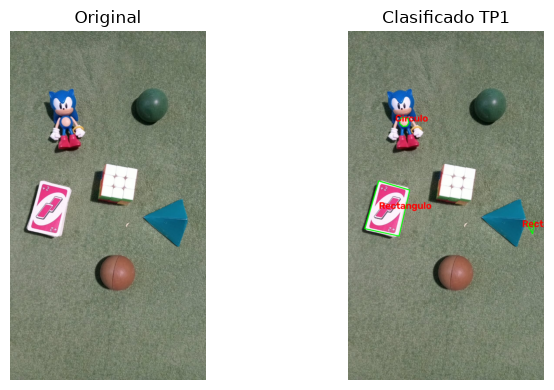

In [ ]:
# Línea base: misma detección por Canny y misma función de formas del TP1
img = cv2.imread(str(DIR_IMAGENES/"01_cesped_6objetos.jpg"))
resultado, detecciones = clasificar_formas(img)
print(f"Contornos analizados: {len(detecciones)}")
print([d["tipo"] for d in detecciones])
mostrar([img, resultado], ["Original", "Clasificado TP1"], cols=2)

## 2. Adquisición y formatos

- Armar un conjunto propio de **al menos 8 imágenes** con formas, en condiciones variadas.
- Comparar una misma imagen guardada en **BMP, PNG y JPEG** (tamaño y calidad).


In [ ]:
# Mide cuánto se parece una imagen a otra, y se usa para comparar calidad
def psnr(a, b):
    """PSNR en dB entre dos imágenes de 8 bits (misma fórmula que cv2.PSNR)."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)


def cargar_imagenes(rutas):
    """Carga una lista de imágenes desde disco (BGR)."""
    imagenes = {}
    for ruta in rutas:
        img = cv2.imread(ruta)
        if img is None:
            print(f"No se pudo leer: {ruta}")
            continue
        imagenes[os.path.basename(ruta)] = img
    return imagenes


def comparar_formatos(img_bgr, nombre_base="muestra"):
    """Guarda la misma imagen en BMP, PNG y JPEG y compara tamaño en disco y calidad.

    Pista: cv2.imwrite(f"{nombre_base}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
           os.path.getsize(ruta) para el tamaño en bytes.
    """
    rutas = {"BMP": f"{nombre_base}.bmp",
             "PNG": f"{nombre_base}.png",
             "JPEG": f"{nombre_base}.jpg"}

    cv2.imwrite(rutas["BMP"], img_bgr)
    cv2.imwrite(rutas["PNG"], img_bgr)
    cv2.imwrite(rutas["JPEG"], img_bgr, [cv2.IMWRITE_JPEG_QUALITY, 90])

    tam_bmp = os.path.getsize(rutas["BMP"])
    tabla = {}
    print(f"{'Formato':<8}{'Tamaño (KB)':>14}{'% del BMP':>12}{'PSNR (dB)':>16}")
    for formato, ruta in rutas.items():
        tam = os.path.getsize(ruta)
        leida = cv2.imread(ruta)
        if np.array_equal(leida, img_bgr):
            calidad = "sin pérdida"
        else:
            calidad = f"{psnr(img_bgr, leida):.2f}"
        tabla[formato] = {"kb": tam / 1024, "porcentaje": 100 * tam / tam_bmp, "psnr": calidad}
        print(f"{formato:<8}{tam / 1024:>14.2f}{100 * tam / tam_bmp:>12.2f}{calidad:>16}")
    return tabla

Imágenes cargadas: 10


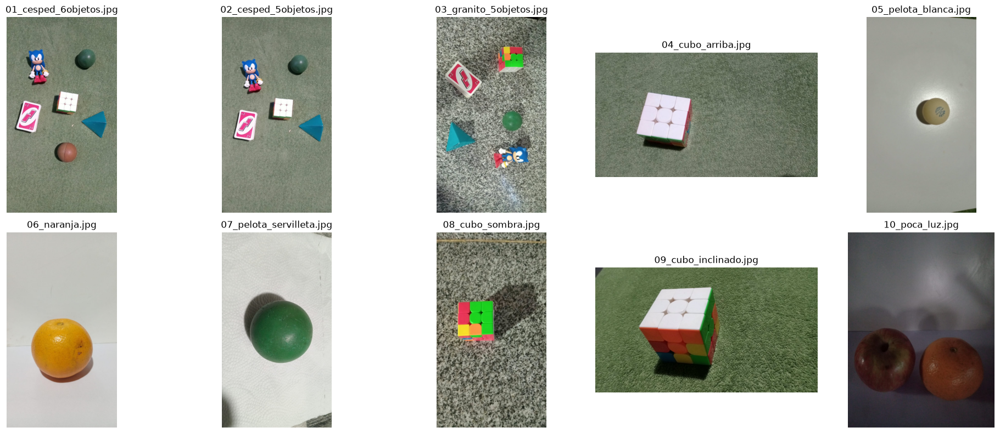

Formato    Tamaño (KB)   % del BMP       PSNR (dB)
BMP            4218.80      100.00     sin pérdida
PNG            3162.07       74.95     sin pérdida
JPEG            490.89       11.64           44.73


In [ ]:
rutas = sorted(str(p) for p in DIR_IMAGENES.glob("*.jpg"))
imgs = cargar_imagenes(rutas)
assert len(imgs) == 10, "El conjunto de referencia debe tener diez imágenes"
print(f"Imágenes cargadas: {len(imgs)}")
mostrar(list(imgs.values()), list(imgs.keys()), cols=5)
# Se guardan los tres formatos en una carpeta temporal para medir sus tamaños reales.
# Los archivos se eliminan automáticamente al finalizar la comparación.
with tempfile.TemporaryDirectory() as carpeta_formatos:
    tabla = comparar_formatos(imgs["01_cesped_6objetos.jpg"],
                              nombre_base=str(Path(carpeta_formatos)/"muestra"))

**Decisiones y observaciones:**

Se comparó la misma imagen (`01_cesped_6objetos.jpg`, 900 px de ancho × 1600 px de alto) guardada en BMP, PNG y JPEG con `cv2.imwrite`. El JPEG se guardó con `cv2.IMWRITE_JPEG_QUALITY = 90`. El tamaño en disco se midió con `os.path.getsize` y la calidad con la función `psnr`, equivalente a `cv2.PSNR`.

| Formato | Tamaño (KB) | % del BMP | Calidad |
|---|---|---|---|
| BMP | 4218,80 | 100,00 | sin pérdida |
| PNG | 3162,07 | 74,95 | sin pérdida |
| JPEG (calidad 90) | 490,89 | 11,64 | PSNR 44,73 dB |

1. **Qué pesa más:** el BMP, porque guarda cada píxel sin comprimir: 1600 × 900 × 3 bytes = 4.320.000 bytes, unos 4218,75 KB.
2. **PNG:** comprime sin perder datos (al leerlo es idéntico al original), pero en esta foto solo ahorra 25,05 %, porque la textura del césped se comprime poco.
3. **JPEG:** es el más liviano (8,59 veces menos que el BMP), pero **pierde información**. Con calidad 90 la diferencia es chica: 44,73 dB, y por encima de 40 dB casi no se nota a simple vista.
4. **Por qué pierde calidad:** JPEG descarta detalles finos que el ojo percibe poco (transformada y cuantización de coeficientes). Eso lo achica, pero no se puede recuperar el original.
5. **Decisión:** las fotografías disponibles son JPEG y se procesan después de decodificarlas, sin recomprimir entre etapas. Para conservar resultados intermedios se recomienda PNG.

La referencia del PSNR es el JPEG ya decodificado: BMP y PNG conservan esos píxeles,
pero no recuperan la información perdida en la captura JPEG. Un PSNR alto no garantiza
por sí solo que desaparezcan los artefactos visuales.

*Nota: la comparación se hizo con una sola imagen; con una imagen lisa  PNG se comprimiría mucho más.*

Los archivos BMP, PNG y JPEG se guardan en una carpeta temporal para medir el tamaño real en disco y se eliminan automáticamente después de la comparación; la tabla queda en esta notebook.

## 3. Mejora y restauración

- Cuantización de niveles de gris y submuestreo (**aliasing**).
- Contraste: ajuste lineal, **corrección gamma** y **ecualización de histograma**.
- Ruido (**sal y pimienta** y **gaussiano**) y comparación de filtros media / gaussiano / mediana.


In [ ]:
def cuantizar(img_gray, niveles):
    """Reduce la imagen a 'niveles' de gris.

    Pista: paso = 256 // niveles; (img // paso) * paso
    """
    paso = 256 // niveles
    return ((img_gray // paso) * paso).astype(np.uint8)


def submuestrear(img, factor):
    """Reduce y vuelve a ampliar para evidenciar aliasing.

    Pista: cv2.resize hacia abajo y luego hacia arriba con INTER_NEAREST.
    """
    alto, ancho = img.shape[:2]
    chica = cv2.resize(img, (int(ancho * factor), int(alto * factor)),
    interpolation=cv2.INTER_NEAREST)
    return cv2.resize(chica, (ancho, alto), interpolation=cv2.INTER_NEAREST)



def ajuste_lineal(img, alpha=1.5, beta=0):
    """Contraste/brillo lineal. Pista: cv2.convertScaleAbs(img, alpha=alpha, beta=beta)."""
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def correccion_gamma(img, gamma=1.0):
    """Corrección gamma usando una LUT.

    Pista: tabla = ((np.arange(256)/255.0) ** gamma) * 255 -> cv2.LUT(img, tabla.astype('uint8'))
    """
    tabla = ((np.arange(256) / 255.0) ** gamma) * 255
    return cv2.LUT(img, tabla.astype("uint8"))


def ecualizar(img_gray):
    """Ecualización de histograma. Pista: cv2.equalizeHist (o CLAHE)."""
    return cv2.equalizeHist(img_gray)


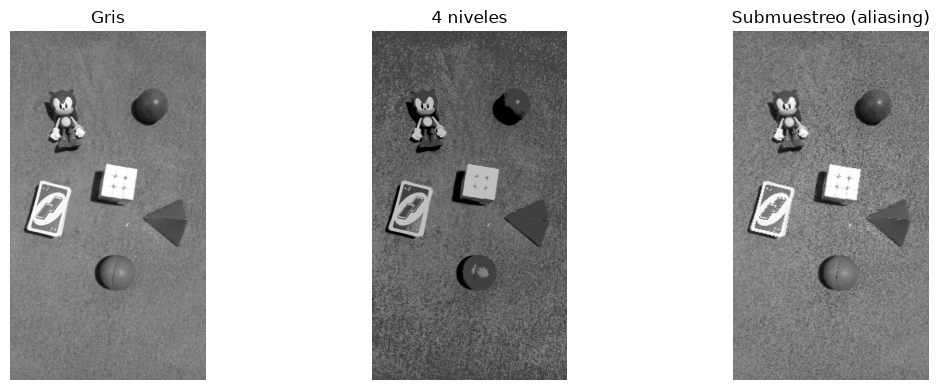

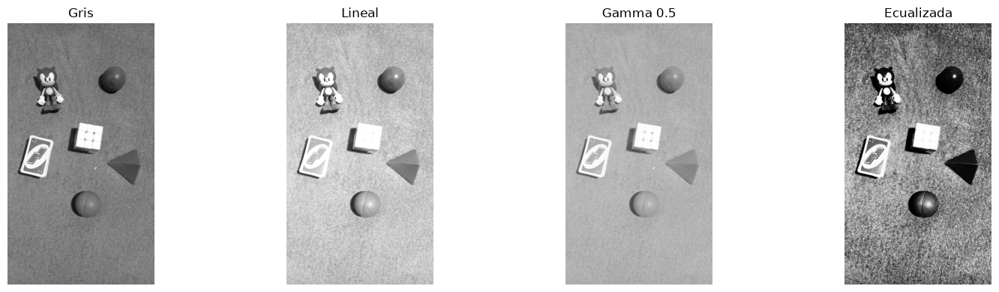

In [ ]:
img = imgs["01_cesped_6objetos.jpg"]
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

mostrar([gris, cuantizar(gris, 4), submuestrear(gris, 0.25)],
        ["Gris", "4 niveles", "Submuestreo (aliasing)"])
mostrar([gris, ajuste_lineal(gris, 1.5, 10), correccion_gamma(gris, 0.5), ecualizar(gris)],
        ["Gris", "Lineal", "Gamma 0.5", "Ecualizada"], cols=4)

In [ ]:
for nombre, im in [("Original", gris), ("4 niveles", cuantizar(gris, 4)),
                   ("Lineal", ajuste_lineal(gris, 1.5, 10)),
                   ("Gamma 0.5", correccion_gamma(gris, 0.5)),
                   ("Gamma 2.0", correccion_gamma(gris, 2.0)),
                   ("Ecualizada", ecualizar(gris))]:
    print(f"{nombre:<12} media = {im.mean():.2f}   niveles distintos = {len(np.unique(im))}")

Original     media = 124.81   niveles distintos = 253
4 niveles    media = 92.25   niveles distintos = 4
Lineal       media = 192.92   niveles distintos = 162
Gamma 0.5    media = 176.32   niveles distintos = 190
Gamma 2.0    media = 64.71   niveles distintos = 192
Ecualizada   media = 129.23   niveles distintos = 102


**Ruido y filtros**

In [ ]:
def ruido_sal_pimienta(img, prob=0.02):
    """Agrega ruido sal y pimienta. Pista: máscara aleatoria -> píxeles a 0 y a 255."""
    ruidosa = img.copy()
    azar = np.random.default_rng(7).random(img.shape[:2])
    ruidosa[azar < prob / 2] = 0            # pimienta (negro)
    ruidosa[azar > 1 - prob / 2] = 255      # sal (blanco)
    return ruidosa


def ruido_gaussiano(img, sigma=20):
    """Agrega ruido gaussiano. Pista: np.random.normal(0, sigma, img.shape) y sumar (clip 0-255)."""
    ruido = np.random.default_rng(7).normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + ruido, 0, 255).astype(np.uint8)


def comparar_filtros(img_ruidosa, img_original=None, ventana=3):
    """Aplica filtro de media, gaussiano y mediana y los muestra para comparar."""
    filtradas = {
        "Media": cv2.blur(img_ruidosa, (ventana, ventana)),
        "Gaussiano": cv2.GaussianBlur(img_ruidosa, (ventana, ventana), 0),
        "Mediana": cv2.medianBlur(img_ruidosa, ventana),
    }
    if img_original is not None:
        print(f"PSNR con ruido: {psnr(img_original, img_ruidosa):.2f} dB")
        for nombre, f in filtradas.items():
            print(f"PSNR {nombre:<10}: {psnr(img_original, f):.2f} dB")
    imagenes_comparadas = ([img_original] if img_original is not None else []) + [img_ruidosa] + list(filtradas.values())
    titulos = (["Original sin ruido agregado"] if img_original is not None else []) + ["Con ruido"] + list(filtradas.keys())
    mostrar(imagenes_comparadas, titulos, cols=len(imagenes_comparadas))
    return filtradas

--- Sal y pimienta (2 %) ---
PSNR con ruido: 22.74 dB
PSNR Media     : 26.04 dB
PSNR Gaussiano : 27.11 dB
PSNR Mediana   : 27.31 dB


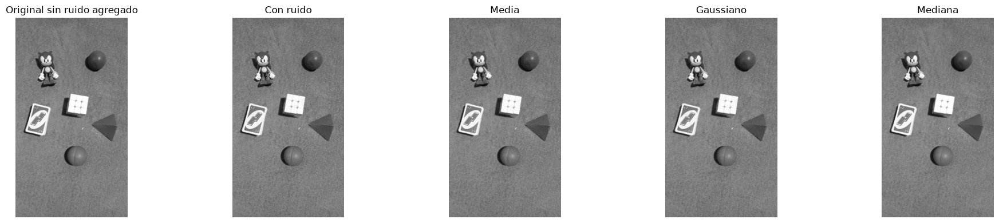

--- Gaussiano (sigma 20) ---
PSNR con ruido: 22.18 dB
PSNR Media     : 25.92 dB
PSNR Gaussiano : 26.93 dB
PSNR Mediana   : 25.30 dB


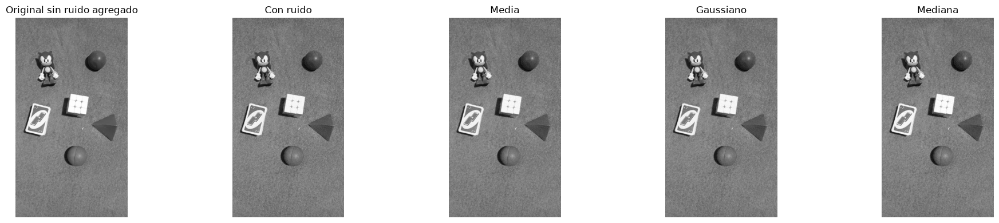

--- Sal y pimienta con ventana 7 ---
PSNR con ruido: 22.74 dB
PSNR Media     : 24.28 dB
PSNR Gaussiano : 25.59 dB
PSNR Mediana   : 24.60 dB


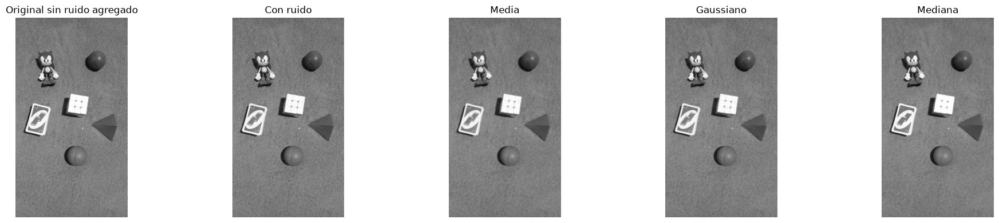

In [ ]:
print("--- Sal y pimienta (2 %) ---")
ruidosa = ruido_sal_pimienta(gris, 0.02)
_ = comparar_filtros(ruidosa, gris)

print("--- Gaussiano (sigma 20) ---")
ruidosa_g = ruido_gaussiano(gris, 20)
_ = comparar_filtros(ruidosa_g, gris)

print("--- Sal y pimienta con ventana 7 ---")
_ = comparar_filtros(ruidosa, gris, ventana=7)

Original: media = 66.87
Gamma 0.4: media = 145.32
Gamma 0.5: media = 126.94
Gamma 0.7: media = 97.52
Ecualizada: media = 128.90
Ecualizada: píxeles casi blancos (>= 250) = 2.20 %


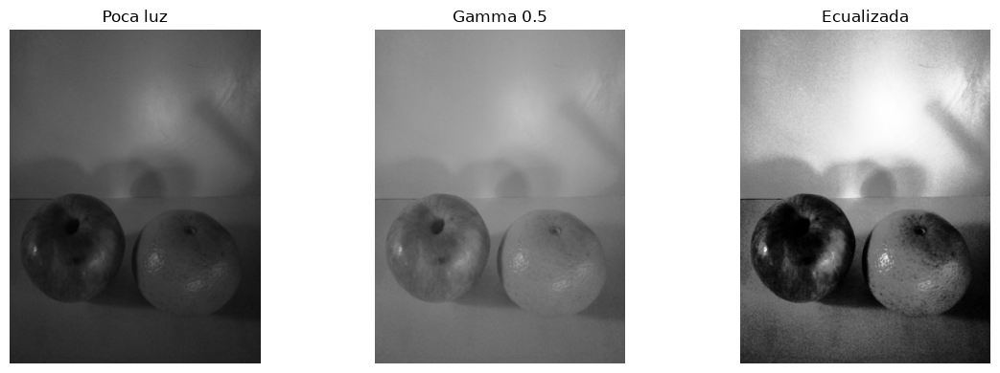

In [ ]:
# Elección de gamma: se prueba sobre la imagen con poca luz
oscura = cv2.cvtColor(imgs["10_poca_luz.jpg"], cv2.COLOR_BGR2GRAY)
print(f"Original: media = {oscura.mean():.2f}")
for g in (0.4, 0.5, 0.7):
    c = correccion_gamma(oscura, g)
    print(f"Gamma {g}: media = {c.mean():.2f}")
e = ecualizar(oscura)
print(f"Ecualizada: media = {e.mean():.2f}")
print(f"Ecualizada: píxeles casi blancos (>= 250) = {100 * np.mean(e >= 250):.2f} %")

mostrar([oscura, correccion_gamma(oscura, 0.5), ecualizar(oscura)],
        ["Poca luz", "Gamma 0.5", "Ecualizada"])

**Decisiones y observaciones:**

**Contraste (imagen `01_cesped_6objetos.jpg`, bien iluminada, media de gris 124,81).** El ajuste lineal (alpha = 1,5; beta = 10) subió la media a 192,92 y saturó las zonas claras. La gamma 0,5 la subió a 176,32 y la gamma 2,0 la bajó a 64,71. La ecualización dejó la media casi igual (129,23) pero usa todo el rango de grises. Como esta foto ya tiene buena luz, ninguna corrección es necesaria.

**Gamma elegida: 0,5.** Se probó sobre la imagen con poca luz (`10_poca_luz.jpg`, media 66,87). Con gamma 0,5 la media pasó a 126,94, es decir, la zona media de la escala, sin recortar los valores por encima de 255 mediante esta LUT. La gamma 0,4 aclara más (media 145,32) y la 0,7 menos (97,52). La media no demuestra sobreexposición; la elección 0,5 es visual y exploratoria. La ecualización (media 128,90) deja el 2,20 % de los píxeles casi blancos (≥ 250).

**Cuantización y submuestreo.** Con 4 niveles quedan solo 4 grises (0, 64, 128 y 192) y se pierde el degradé. Con submuestreo 0,25 aparecen escalones (aliasing).

**Filtros de ruido (PSNR en dB, más alto es mejor).**

| Caso | Con ruido | Media | Gaussiano | Mediana |
|---|---|---|---|---|
| Sal y pimienta (2 %), ventana 3 | 22,74 | 26,04 | 27,11 | 27,31 |
| Gaussiano (sigma 20), ventana 3 | 22,18 | 25,92 | 26,93 | 25,30 |
| Sal y pimienta, ventana 7 | 22,74 | 24,28 | 25,59 | 24,60 |

- Para **sal y pimienta** funciona mejor la **mediana** (27,31 dB), porque descarta los valores extremos en vez de promediarlos. La ventaja es chica porque el césped tiene mucha textura fina.
- Para **ruido gaussiano** funciona mejor el filtro **gaussiano** (26,93 dB). La mediana queda última (25,30 dB).
- Con ventana 7 todos los filtros dan peor PSNR que con ventana 3, porque borran más detalle. Se eligió ventana 3.

El pipeline revisado conserva la imagen original para segmentar. Para nombrar colores aplica la misma LUT gamma 0,5 a una copia BGR cuando la mediana global de V es menor que 100. Es una heurística para imágenes oscuras, no una corrección del iluminante ni recuperación del color material.

## 4. Transformaciones geométricas y morfología

- Rotación, escalado, traslación y **corrección de perspectiva (homografía)**.
- Erosión, dilatación, apertura y cierre con distintos **elementos estructurantes**.


In [ ]:
def rotar(img, angulo, escala=1.0):
    """Rota la imagen. Pista: cv2.getRotationMatrix2D(centro, angulo, escala) + cv2.warpAffine."""
    alto, ancho = img.shape[:2]
    matriz = cv2.getRotationMatrix2D((ancho / 2, alto / 2), angulo, escala)
    return cv2.warpAffine(img, matriz, (ancho, alto))


def escalar(img, fx, fy):
    """Escala la imagen. Pista: cv2.resize(img, None, fx=fx, fy=fy)."""
    interpolacion = cv2.INTER_AREA if (fx < 1 or fy < 1) else cv2.INTER_CUBIC
    return cv2.resize(img, None, fx=fx, fy=fy, interpolation=interpolacion)


def trasladar(img, tx, ty):
    """Traslada la imagen. Pista: M = np.float32([[1,0,tx],[0,1,ty]]) + cv2.warpAffine."""
    alto, ancho = img.shape[:2]
    matriz = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(img, matriz, (ancho, alto))


def corregir_perspectiva(img, pts_origen, pts_destino, tam_salida=None):
    """Endereza una figura fotografiada en ángulo.

    Pista: M = cv2.getPerspectiveTransform(pts_origen, pts_destino) + cv2.warpPerspective.
    """
    alto, ancho = img.shape[:2]
    if tam_salida is None:
        tam_salida = (ancho, alto)
    matriz = cv2.getPerspectiveTransform(np.float32(pts_origen), np.float32(pts_destino))
    return cv2.warpPerspective(img, matriz, tam_salida)


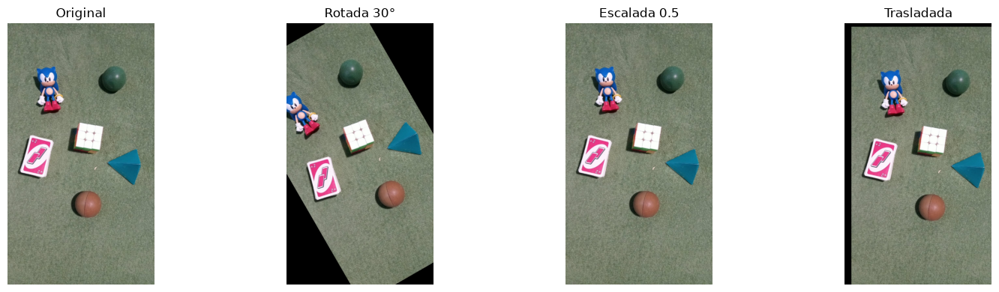

Tamaño original: (1600, 900) | escalada 0.5: (800, 450)


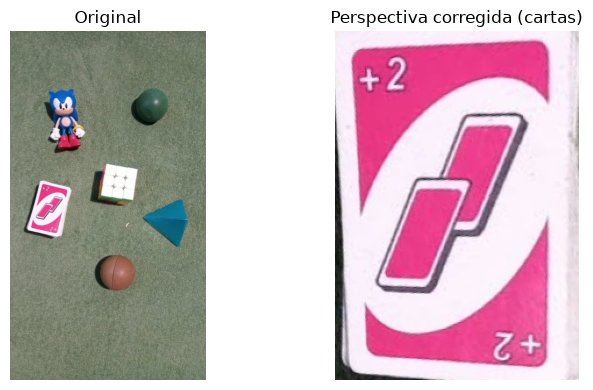

In [ ]:
img = imgs["01_cesped_6objetos.jpg"]
mostrar([img, rotar(img, 30), escalar(img, 0.5, 0.5), trasladar(img, 40, 20)],
        ["Original", "Rotada 30°", "Escalada 0.5", "Trasladada"], cols=4)
print("Tamaño original:", img.shape[:2], "| escalada 0.5:", escalar(img, 0.5, 0.5).shape[:2])

# Esquinas del mazo de cartas (orden: sup-izq, sup-der, inf-der, inf-izq)
pts_o = np.float32([[142, 686], [281, 728], [232, 938], [65, 916]])
pts_d = np.float32([[0, 0], [210, 0], [210, 300], [0, 300]])
carta = corregir_perspectiva(img, pts_o, pts_d, tam_salida=(210, 300))
mostrar([img, carta], ["Original", "Perspectiva corregida (cartas)"], cols=2)

In [ ]:
def operaciones_morfologicas(img_bin, tam_kernel=5, forma=cv2.MORPH_RECT):
    """Erosión, dilatación, apertura y cierre. Devuelve un dict para comparar.

    Pista: kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (tam, tam));
           cv2.erode / cv2.dilate / cv2.morphologyEx(..., MORPH_OPEN / MORPH_CLOSE).
    """
    kernel = cv2.getStructuringElement(forma, (tam_kernel, tam_kernel))
    apertura = cv2.morphologyEx(img_bin, cv2.MORPH_OPEN, kernel)
    return {
        "Original": img_bin,
        "Erosion": cv2.erode(img_bin, kernel),
        "Dilatacion": cv2.dilate(img_bin, kernel),
        "Apertura": apertura,
        "Cierre": cv2.morphologyEx(img_bin, cv2.MORPH_CLOSE, kernel),
        "Apertura + Cierre": cv2.morphologyEx(apertura, cv2.MORPH_CLOSE, kernel),
    }

Umbral Otsu: 179.0
--- Rectángulo 5x5 ---
Original           blancos= 3.59% componentes=10
Erosion            blancos= 2.83% componentes=9
Dilatacion         blancos= 4.40% componentes=10
Apertura           blancos= 3.52% componentes=8
Cierre             blancos= 3.68% componentes=10
Apertura + Cierre  blancos= 3.56% componentes=8


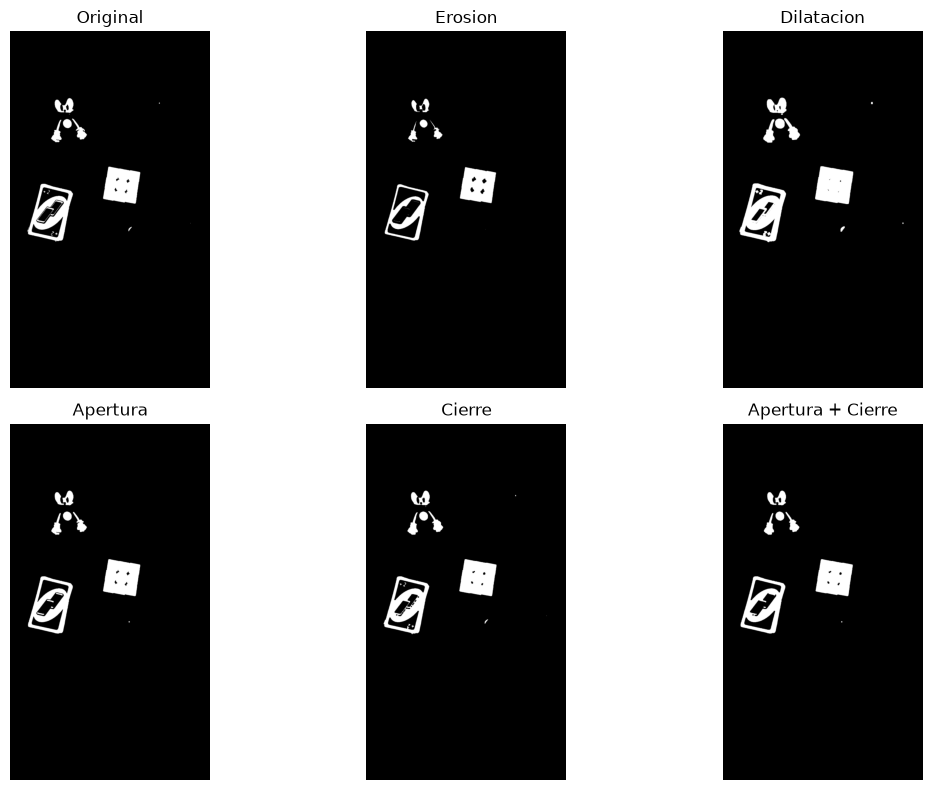

--- Rectángulo 15x15 ---
Original           blancos= 3.59% componentes=10
Erosion            blancos= 1.41% componentes=15
Dilatacion         blancos= 5.97% componentes=7
Apertura           blancos= 2.95% componentes=10
Cierre             blancos= 4.00% componentes=7
Apertura + Cierre  blancos= 3.01% componentes=9


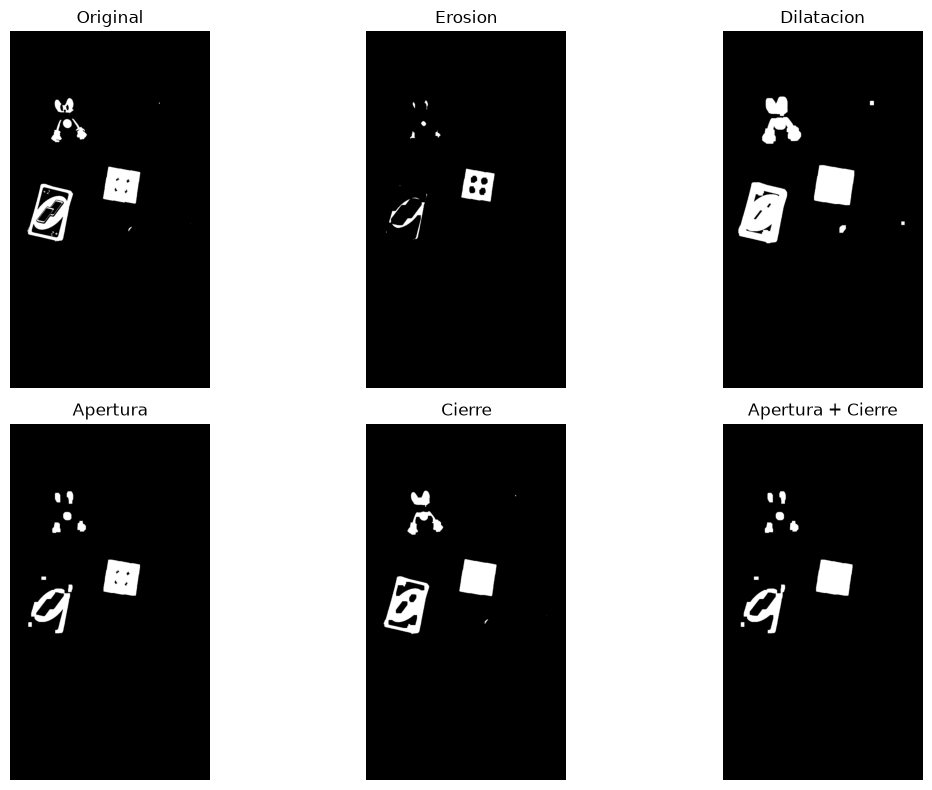

--- Elipse 5x5 ---
Original           blancos= 3.59% componentes=10
Erosion            blancos= 2.95% componentes=8
Dilatacion         blancos= 4.27% componentes=10
Apertura           blancos= 3.54% componentes=8
Cierre             blancos= 3.64% componentes=10
Apertura + Cierre  blancos= 3.57% componentes=8


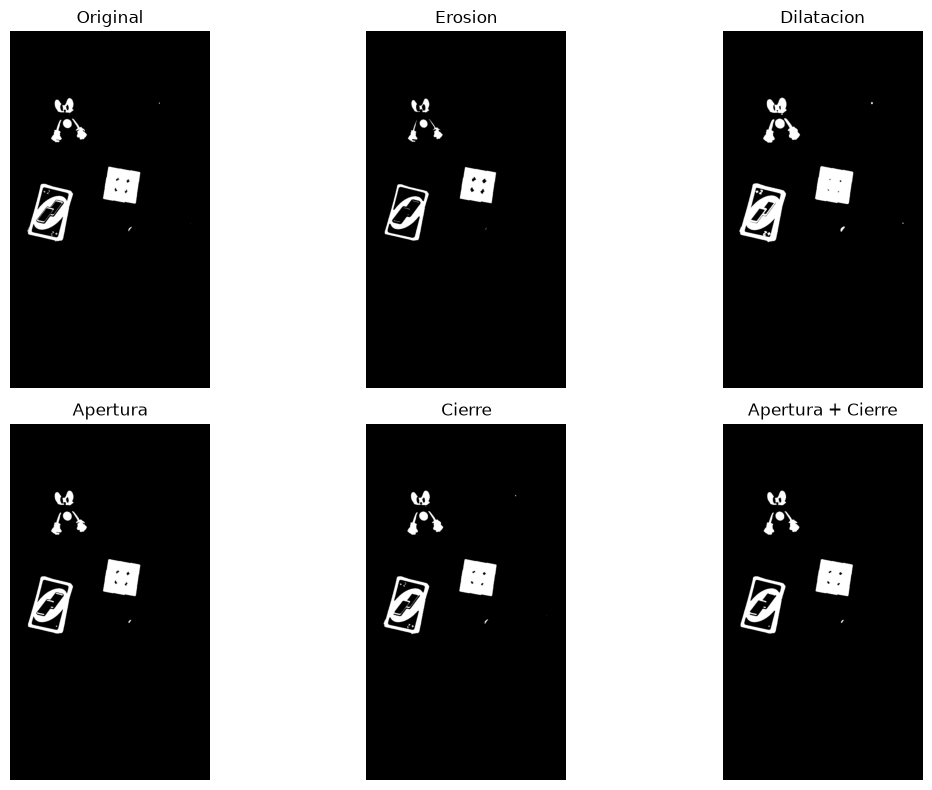

--- Elipse 15x15 ---
Original           blancos= 3.59% componentes=10
Erosion            blancos= 1.69% componentes=28
Dilatacion         blancos= 5.61% componentes=7
Apertura           blancos= 3.19% componentes=9
Cierre             blancos= 3.92% componentes=7
Apertura + Cierre  blancos= 3.28% componentes=7


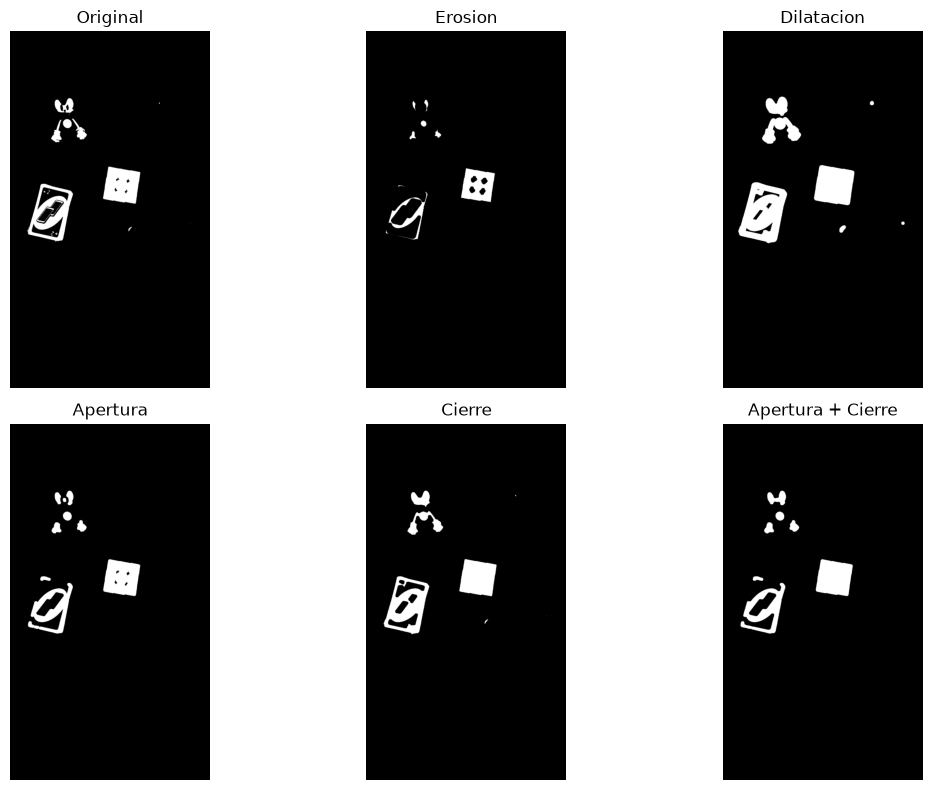

--- Cruz 5x5 ---
Original           blancos= 3.59% componentes=10
Erosion            blancos= 3.02% componentes=8
Dilatacion         blancos= 4.19% componentes=10
Apertura           blancos= 3.54% componentes=8
Cierre             blancos= 3.64% componentes=10
Apertura + Cierre  blancos= 3.57% componentes=7


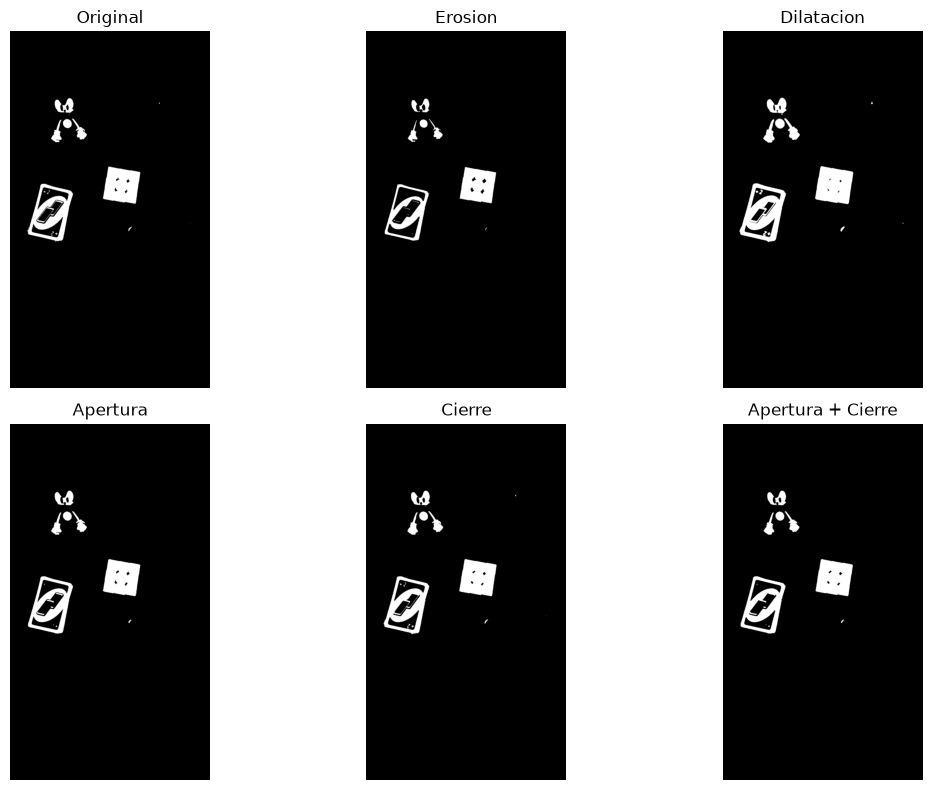

--- Cruz 15x15 ---
Original           blancos= 3.59% componentes=10
Erosion            blancos= 1.89% componentes=36
Dilatacion         blancos= 5.38% componentes=7
Apertura           blancos= 3.16% componentes=9
Cierre             blancos= 3.88% componentes=7
Apertura + Cierre  blancos= 3.22% componentes=9


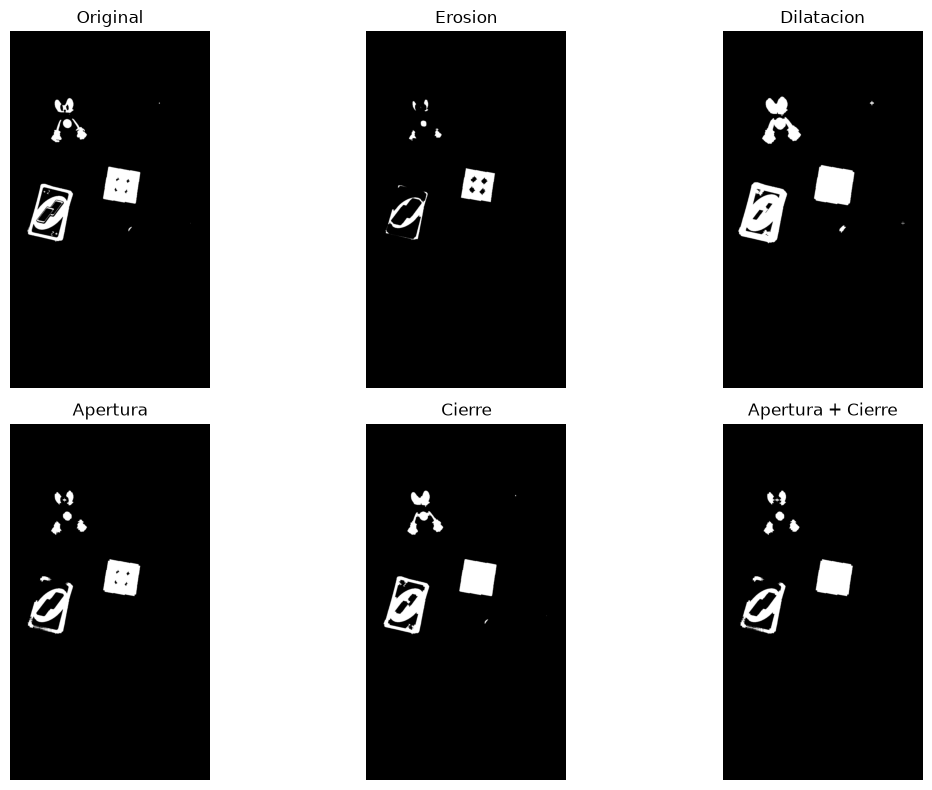

In [ ]:
umbral_morf, mascara_bin = cv2.threshold(cv2.GaussianBlur(gris, (5, 5), 0), 0, 255,
                                        cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Umbral Otsu:", umbral_morf)
for nombre_forma, forma in [("Rectángulo",cv2.MORPH_RECT), ("Elipse",cv2.MORPH_ELLIPSE), ("Cruz",cv2.MORPH_CROSS)]:
    for tam in (5,15):
        print(f"--- {nombre_forma} {tam}x{tam} ---")
        morf = operaciones_morfologicas(mascara_bin,tam,forma)
        for nombre,m in morf.items():
            componentes = len(cv2.findContours(m,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)[0])
            print(f"{nombre:<18} blancos={100*np.mean(m==255):5.2f}% componentes={componentes}")
        mostrar(list(morf.values()),list(morf.keys()),cols=3,cmap="gray")

**Decisiones y observaciones:**

**Transformaciones geométricas.** Con `cv2.getRotationMatrix2D` y `cv2.warpAffine` se rotó 30°; la imagen conserva el tamaño del lienzo y pueden cortarse las esquinas. Con `cv2.resize` se escaló a la mitad, de 900 × 1600 a 450 × 800 px (ancho × alto), usando `INTER_AREA` para reducir artefactos de aliasing. La traslación de 40 px en x y 20 px en y usa la matriz `[[1,0,tx],[0,1,ty]]` con `cv2.warpAffine`; también puede recortar contenido al mantener el lienzo. Para corregir la perspectiva se marcaron manualmente las cuatro esquinas del mazo de cartas, ordenadas en el mismo sentido, y `cv2.getPerspectiveTransform` + `cv2.warpPerspective` produjeron un rectángulo de 210 × 300 px. Esta homografía rectifica una figura plana; no endereza automáticamente objetos 3D ni se aplica automáticamente en el pipeline.

**Elementos estructurantes.** Se compararon rectángulos (`MORPH_RECT`), elipses (`MORPH_ELLIPSE`) y cruces (`MORPH_CROSS`), de 5 × 5 y 15 × 15, sobre la misma máscara binaria obtenida con suavizado gaussiano 5 × 5 y Otsu (umbral 179). Para cada operación se midieron el porcentaje de píxeles blancos y los contornos externos.

**Rectángulo.**

| Operación | Kernel 5: blancos % | Componentes | Kernel 15: blancos % | Componentes |
|---|---:|---:|---:|---:|
| Original | 3,59 | 10 | 3,59 | 10 |
| Erosión | 2,83 | 9 | 1,41 | 15 |
| Dilatación | 4,40 | 10 | 5,97 | 7 |
| Apertura | 3,52 | 8 | 2,95 | 10 |
| Cierre | 3,68 | 10 | 4,00 | 7 |
| Apertura + cierre | 3,56 | 8 | 3,01 | 9 |

**Elipse.**

| Operación | Kernel 5: blancos % | Componentes | Kernel 15: blancos % | Componentes |
|---|---:|---:|---:|---:|
| Original | 3,59 | 10 | 3,59 | 10 |
| Erosión | 2,95 | 8 | 1,69 | 28 |
| Dilatación | 4,27 | 10 | 5,61 | 7 |
| Apertura | 3,54 | 8 | 3,19 | 9 |
| Cierre | 3,64 | 10 | 3,92 | 7 |
| Apertura + cierre | 3,57 | 8 | 3,28 | 7 |

**Cruz.**

| Operación | Kernel 5: blancos % | Componentes | Kernel 15: blancos % | Componentes |
|---|---:|---:|---:|---:|
| Original | 3,59 | 10 | 3,59 | 10 |
| Erosión | 3,02 | 8 | 1,89 | 36 |
| Dilatación | 4,19 | 10 | 5,38 | 7 |
| Apertura | 3,54 | 8 | 3,16 | 9 |
| Cierre | 3,64 | 10 | 3,88 | 7 |
| Apertura + cierre | 3,57 | 7 | 3,22 | 9 |

(Componentes = regiones blancas externas, contadas con `cv2.findContours` y `RETR_EXTERNAL`. No equivalen necesariamente a objetos reales: un mismo objeto puede aparecer fragmentado.)

- **Erosión y dilatación:** la erosión reduce las regiones blancas y la dilatación las expande. Con kernel 15, la erosión deja 1,41 % de área blanca con rectángulo, 1,69 % con elipse y 1,89 % con cruz, frente al 3,59 % original. El conteo puede aumentar por fragmentación: llega a 28 componentes con elipse y 36 con cruz; esto no significa que aparezcan más objetos.
- **Apertura:** con kernel 5, los tres elementos reducen de 10 a 8 componentes y mantienen el área próxima a la original: 3,52 % para rectángulo y 3,54 % para elipse y cruz. Es útil para retirar regiones o detalles menores que el elemento, aunque también puede eliminar partes válidas.
- **Cierre:** rellena huecos pequeños y puede unir regiones cercanas. Con kernel 15, los tres elementos dejan 7 componentes, con áreas de 4,00 % (rectángulo), 3,92 % (elipse) y 3,88 % (cruz). La reducción del conteo debe contrastarse con las imágenes para comprobar que no se fusionen objetos distintos.
- **Apertura + cierre:** con kernel 5 quedan 8 componentes para rectángulo y elipse y 7 para cruz; las áreas son 3,56 %, 3,57 % y 3,57 %, respectivamente. Con kernel 15 quedan 9, 7 y 9 componentes. Encadenar ambas operaciones no produce siempre el mismo efecto ni garantiza un mejor resultado.
- **Forma del elemento:** el rectángulo considera toda su vecindad, la elipse tiene un soporte más redondeado y la cruz se concentra en las direcciones horizontal y vertical. Sus efectos dependen de cómo encaja ese soporte en los detalles de la máscara; estas tablas no demuestran que una forma sea universalmente superior.
- **Tamaño del elemento:** 15 × 15 produce cambios más fuertes que 5 × 5 y puede borrar detalles, fragmentar regiones o unirlas. El kernel chico conserva más área en esta demostración. Un mayor o menor número de componentes no permite decidir por sí solo qué configuración segmenta mejor.
- **Decisión para el pipeline revisado:** se procesa una imagen con lado máximo de 800 px y se utiliza apertura elíptica 5 × 5 y cierre elíptico 9 × 9 con dos iteraciones. Se agrega un cierre 15 × 15 con dos iteraciones solo para unir grupos de fragmentos cuyo tamaño individual sea menor al 1 % de la imagen, antes del refinamiento con GrabCut; después se aplica cierre 5 × 5. Son parámetros globales exploratorios para este conjunto, sin ajustes por fotografía. La evaluación por objeto de las secciones siguientes permite valorar el sistema completo.

## 5. Detección de bordes y segmentación

- Comparar **Sobel, Prewitt y Laplaciano** (y **Canny**).
- Segmentar las figuras del fondo (**umbralización / Otsu**) y **contar cuántas hay**.



In [ ]:
def detectar_bordes(img_gray):
    """Aplica Sobel, Prewitt, Laplaciano y Canny. Devuelve un dict {nombre: imagen}.

    Pista Prewitt: kernels manuales con cv2.filter2D
        kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]]); ky = kx.T
    """
    suave = cv2.GaussianBlur(img_gray, (5, 5), 0)      # derivar amplifica el ruido: se suaviza antes
    f = suave.astype(np.float32)

    sx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3)
    sy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)

    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
    ky = kx.T
    px = cv2.filter2D(f, cv2.CV_32F, kx)
    py = cv2.filter2D(f, cv2.CV_32F, ky)

    def a_uint8(mapa):
        return cv2.normalize(np.abs(mapa), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return {
        "Sobel": a_uint8(cv2.magnitude(sx, sy)),
        "Prewitt": a_uint8(cv2.magnitude(px, py)),
        "Laplaciano": a_uint8(cv2.Laplacian(f, cv2.CV_32F, ksize=3)),
        "Canny": cv2.Canny(suave, 50, 150),
    }


def segmentar_otsu(img_gray):
    """Binariza con Otsu. Pista: cv2.threshold(img, 0, 255, THRESH_BINARY_INV + THRESH_OTSU)."""
    suave = cv2.GaussianBlur(img_gray, (5, 5), 0)
    _, binaria = cv2.threshold(suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if np.mean(binaria == 255) > 0.5:       # el fondo suele ser lo que más ocupa: si el blanco
        binaria = cv2.bitwise_not(binaria)  # supera la mitad, se invierte para que las figuras queden en blanco
    return binaria


def contar_figuras(img_bin, area_min_frac=0.0005):
    """Cuenta las figuras presentes: contornos externos con área mayor al mínimo."""
    contornos, _ = cv2.findContours(img_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    area_minima = img_bin.shape[0] * img_bin.shape[1] * area_min_frac
    return sum(1 for c in contornos if cv2.contourArea(c) > area_minima)

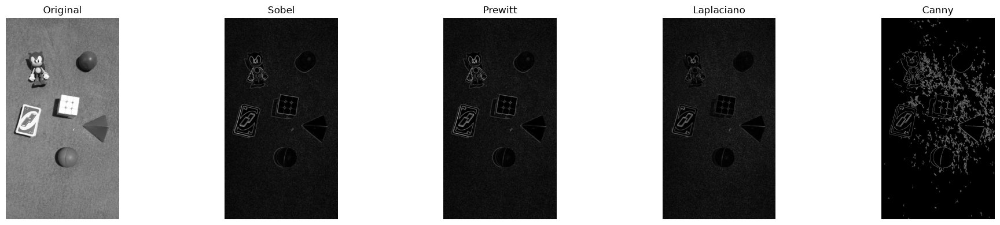

Sobel       píxeles >= 128: 0.35 %
Prewitt     píxeles >= 128: 0.35 %
Laplaciano  píxeles >= 128: 0.08 %
Canny       píxeles >= 128: 3.60 %
Figuras detectadas: 6


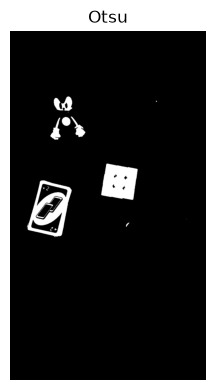


Foto                        Reales   Otsu
01_cesped_6objetos.jpg           6      6
02_cesped_5objetos.jpg           5      6
03_granito_5objetos.jpg          5     60
04_cubo_arriba.jpg               1      1
05_pelota_blanca.jpg             1      5
06_naranja.jpg                   1      1
07_pelota_servilleta.jpg         1      4
08_cubo_sombra.jpg               1     95
09_cubo_inclinado.jpg            1      1
10_poca_luz.jpg                  2      4


In [ ]:
bordes = detectar_bordes(gris)
mostrar([gris]+list(bordes.values()), ["Original"]+list(bordes.keys()), cols=5, cmap="gray")
for nombre, m in bordes.items():
    print(f"{nombre:<11} píxeles >= 128: {100 * np.mean(m >= 128):.2f} %")

binaria = segmentar_otsu(gris)
print(f"Figuras detectadas: {contar_figuras(binaria)}")
mostrar(binaria, "Otsu", cmap="gray")

# Conteo en todas las fotos, contra lo que hay de verdad
reales = {"01": 6, "02": 5, "03": 5, "04": 1, "05": 1, "06": 1, "07": 1, "08": 1, "09": 1, "10": 2}
print(f"\n{'Foto':<26}{'Reales':>8}{'Otsu':>7}")
for nombre, im in imgs.items():
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    print(f"{nombre:<26}{reales[nombre[:2]]:>8}{contar_figuras(segmentar_otsu(g)):>7}")

**Decisiones y observaciones:**

**Bordes (imagen `01_cesped_6objetos.jpg`).** Se aplicó un suavizado gaussiano 5 × 5 antes de derivar, porque derivar amplifica el ruido. Se muestran los operadores y, como descriptor de cada salida, el porcentaje de píxeles con valor ≥128:

| Operador | Píxeles ≥ 128 |
|---|---|
| Sobel | 0,35 % |
| Prewitt | 0,35 % |
| Laplaciano | 0,08 % |
| Canny | 3,60 % |

- **Sobel y Prewitt** dan resultados casi idénticos: ambos calculan el gradiente en x e y y se diferencian solo en los pesos del kernel.
- **Laplaciano** (derivada de segundo orden) marca menos píxeles fuertes y es más sensible al ruido.
- **Canny** produce bordes finos mediante supresión de no máximos e histéresis (50,150); no garantiza contornos cerrados. Es el método utilizado por la línea base.

**Límite de la comparación:** Sobel, Prewitt y Laplaciano se normalizan individualmente
a [0,255], mientras que Canny devuelve una máscara binaria. Por eso estos porcentajes
no son una medida común de calidad ni permiten ordenar la precisión de los detectores.

**Segmentación con Otsu.** Otsu elige el umbral solo a partir del histograma (en la foto del césped dio 179). Contra la cantidad real de figuras:

| Foto | Reales | Otsu |
|---|---|---|
| 01_cesped_6objetos | 6 | 6 |
| 02_cesped_5objetos | 5 | 6 |
| 03_granito_5objetos | 5 | 60 |
| 04_cubo_arriba | 1 | 1 |
| 05_pelota_blanca | 1 | 5 |
| 06_naranja | 1 | 1 |
| 07_pelota_servilleta | 1 | 4 |
| 08_cubo_sombra | 1 | 95 |
| 09_cubo_inclinado | 1 | 1 |
| 10_poca_luz | 2 | 4 |

- Otsu acierta cuando hay **un objeto sobre un fondo liso** (fotos 04, 06 y 09).
- En la foto 01 el 6 es una coincidencia: Otsu detectó solo las cartas, el cubo y Sonic (partido en 4 pedazos), y **no detectó** la bola verde, la bola marrón ni el triángulo, porque en grises son oscuros como el césped.
- Con fondo con textura (granito, 60 figuras) o sombra larga (foto 08, 95 figuras), Otsu genera cientos de manchas, porque usa solo el brillo.
- Conclusión: la umbralización en grises no alcanza para fotos reales. El pipeline anterior usa Otsu con morfología; el revisado de la sección 7 incorpora **distancia cromática al fondo, saturación y luminancia**, seguidas de GrabCut.

## 6. Color

- Separar los canales **RGB** y convertir a **HSV**.
- Segmentar las figuras **por color** en HSV y aplicar un **mapa de pseudocolor**.


In [ ]:
def separar_canales(img_bgr):
    """Separa los canales B, G, R. Pista: cv2.split."""
    b, g, r = cv2.split(img_bgr)
    return b, g, r


def a_hsv(img_bgr):
    """Convierte a HSV. Pista: cv2.cvtColor(img, cv2.COLOR_BGR2HSV)."""
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)


def segmentar_por_color(img_bgr, rango_bajo, rango_alto):
    """Devuelve una máscara con los píxeles dentro del rango HSV indicado."""
    return cv2.inRange(a_hsv(img_bgr), np.array(rango_bajo), np.array(rango_alto))


# Rangos de tono (H de OpenCV va de 0 a 179). El rojo da la vuelta, por eso aparece dos veces.
RANGOS_TONO = [("rojo", 0, 10), ("naranja", 10, 22), ("amarillo", 22, 35), ("verde", 35, 85),
               ("celeste", 85, 100), ("azul", 100, 130), ("violeta", 130, 150),
               ("rosa", 150, 170), ("rojo", 170, 180)]


def color_dominante(img_bgr, mascara=None):
    """Devuelve el nombre del color predominante (rojo/verde/azul/amarillo/...)."""
    hsv = a_hsv(img_bgr)
    if mascara is None:
        mascara = np.full(img_bgr.shape[:2], 255, dtype=np.uint8)
    pixeles = hsv[mascara > 0]
    if len(pixeles) == 0:
        return "sin datos"

    h, s, v = pixeles[:, 0], pixeles[:, 1], pixeles[:, 2]

    con_color = (s >= 50) & (v >= 50)          # sin saturación o muy oscuro, el tono no es confiable
    if con_color.mean() < 0.5:
        brillo = np.median(v)
        if brillo < 60:
            return "negro"
        return "blanco" if brillo > 200 else "gris"

    tonos = h[con_color]
    pesos = s[con_color].astype(np.float64)    # cada píxel vota con su saturación
    cuentas = {}
    for nombre, bajo, alto in RANGOS_TONO:
        en_rango = (tonos >= bajo) & (tonos < alto)
        cuentas[nombre] = cuentas.get(nombre, 0.0) + float(pesos[en_rango].sum())
    return max(cuentas, key=cuentas.get)


def pseudocolor(img_gray, colormap=cv2.COLORMAP_JET):
    """Aplica un mapa de pseudocolor. Pista: cv2.applyColorMap(img, colormap)."""
    return cv2.applyColorMap(img_gray, colormap)

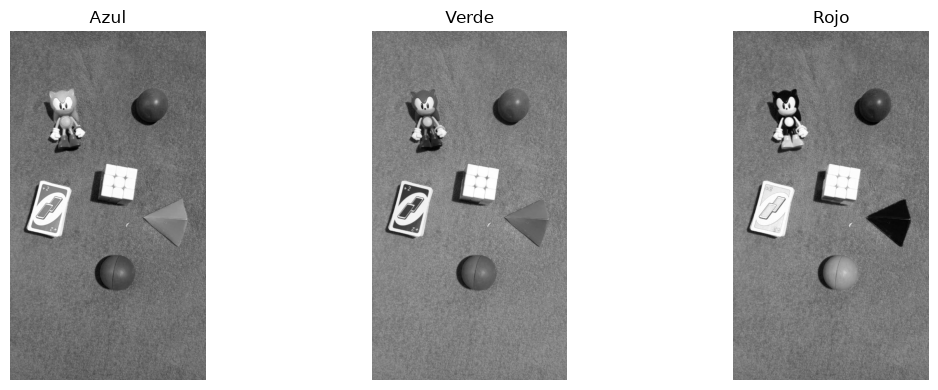

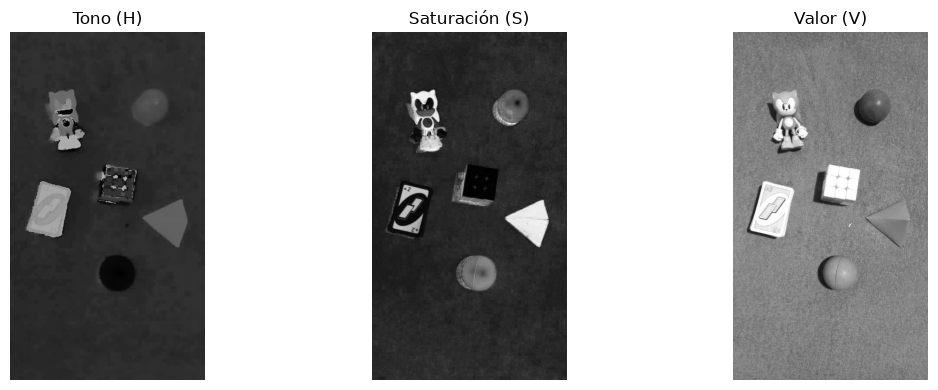

Píxeles verdes: 8.42 %


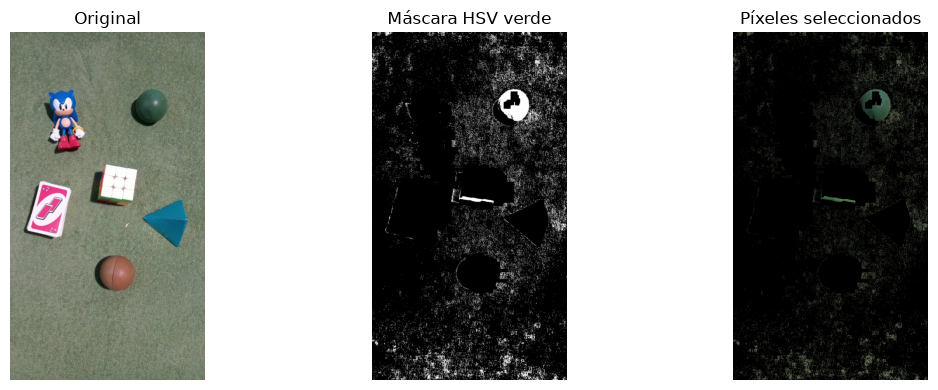

Color dominante (foto entera): gris
  Sonic        azul
  bola verde   verde
  cartas       rosa
  cubo         blanco
  bola marrón  rojo
  triángulo    celeste


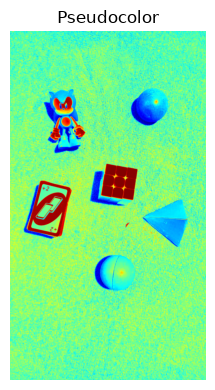

In [ ]:
b, g, r = separar_canales(img)
mostrar([b, g, r], ["Azul", "Verde", "Rojo"], cmap="gray")

h, s, v = cv2.split(a_hsv(img))
mostrar([h, s, v], ["Tono (H)", "Saturación (S)", "Valor (V)"], cmap="gray")

# Rango HSV para verde (el de la plantilla)
mascara = segmentar_por_color(img, np.array([40, 50, 50]), np.array([80, 255, 255]))
print(f"Píxeles verdes: {100 * np.mean(mascara > 0):.2f} %")
mostrar([img, mascara, cv2.bitwise_and(img,img,mask=mascara)], ["Original","Máscara HSV verde","Píxeles seleccionados"], cols=3)

print("Color dominante (foto entera):", color_dominante(img))
objetos = {"Sonic": (249, 411), "bola verde": (620, 367), "cartas": (175, 820),
           "cubo": (476, 703), "bola marrón": (480, 1108), "triángulo": (733, 872)}
for nombre, (x, y) in objetos.items():
    print(f"  {nombre:<12}", color_dominante(img[y - 20:y + 20, x - 20:x + 20]))

mostrar(pseudocolor(gris), "Pseudocolor")

**Decisiones y observaciones:**

**Por qué HSV es mejor que RGB para segmentar por color.** En RGB el color y la luz están mezclados: un mismo objeto verde, bajo sombra o bajo luz fuerte, cambia sus tres canales a la vez, y no hay un rango simple que lo capture. En HSV el **color puro está separado en el tono (H)**, y el brillo y la intensidad quedan en la saturación (S) y el valor (V). Por eso una sombra cambia sobre todo V, pero el tono H casi no se mueve, y un rango de H puede resultar más estable; aun así, sombras fuertes, baja saturación, balance de blancos y cambios de iluminación pueden desplazar el tono.

**Rangos elegidos (H de OpenCV, de 0 a 179; S y V mínimos de 50 para descartar píxeles grises o muy oscuros):**

| Color | H |
|---|---|
| Rojo | 0 a 10 y 170 a 180 (da la vuelta) |
| Naranja | 10 a 22 |
| Amarillo | 22 a 35 |
| Verde | 35 a 85 |
| Celeste | 85 a 100 |
| Azul | 100 a 130 |
| Violeta | 130 a 150 |
| Rosa | 150 a 170 |

Para la máscara de verde se usó el rango `[40, 50, 50]` a `[80, 255, 255]`.

**Resultados (imagen `01_cesped_6objetos.jpg`).**
- La máscara verde marcó el 8,42 % de los píxeles. Incluye la bola verde, pero también el césped, que es verde apagado. Con un fondo del mismo color que el objeto, la segmentación por color sola no alcanza.
- `color_dominante` sobre la foto entera da **gris**: el césped tiene poca saturación y casi ningún píxel supera el umbral de color. El color dominante tiene sentido calculado **por objeto**.
- Sobre un recorte de cada objeto: Sonic = azul, bola verde = verde, cartas = rosa, cubo = blanco, triángulo = celeste. La bola marrón da **rojo**, porque el marrón es un naranja oscuro y su tono cae cerca del rango del rojo; es una limitación de nombrar colores solo por el tono.
- Cada píxel vota con su saturación, de modo que un color vivo pesa más que uno pálido (por ejemplo, una banda de color pesa más que un estampado beige).

**Pseudocolor.** `cv2.applyColorMap` con JET asigna un color a cada nivel de gris, lo que facilita ver diferencias de intensidad que en grises casi no se distinguen.

## 7. Sistema integrador

- Encadenar todo en un **único pipeline** que reciba una imagen real y devuelva, por cada
  forma detectada, su **tipo** y su **color**, más el **conteo total**.
- Comparar la **robustez** del sistema final contra el clasificador del TP1.


**Comparación controlada.** Se conserva el pipeline anterior (gris, mediana,
Otsu, apertura y cierre) para medir el efecto de la revisión, además de la línea base TP1.
La versión revisada combina cromaticidad Lab, saturación HSV y regiones claras respecto
del borde. Refina cada candidato mediante GrabCut, rellena huecos y clasifica la geometría
con medidas que toleran rotación. Las anotaciones no se consultan durante la detección.

**Parámetros y supuestos:** lado máximo 800 px; banda de fondo 4%; umbral cromático
mínimo 12 en a,b de OpenCV o mediana+4σ robusta; diferencias mínimas de luminancia 30
y saturación 35; apertura elíptica 5×5; cierre 9×9 con dos iteraciones; cierre 15×15
adicional solo si une varios componentes cuyo tamaño individual es menor al 1% de la imagen; GrabCut tres
iteraciones; área mínima 0,2%. Se asumen objetos interiores y separados y fondo visible
en el borde. El umbral de área y los kernels pueden perder objetos pequeños o fusionar vecinos.

Para clasificar formas se usa la envolvente convexa y un polígono con tolerancia del
5% de su perímetro. Se exige solidez ≥0,86; para círculos, ocupación del círculo mínimo
≥0,78, circularidad de la envolvente ≥0,85 y solidez ≥0,90. Los cuadriláteros deben
ocupar más del 78% del rectángulo rotado; una ocupación ≥85% permite tolerar pequeños
vértices adicionales. La razón de lados ≥0,85 distingue cuadrados de rectángulos.
Una segunda aproximación al 7,5% permite reconocer triángulos con un vértice espurio,
solo si ocupan menos del 70% de su rectángulo. Son heurísticas geométricas,
no una demostración de reconocimiento invariante a perspectiva.

El color usa píxeles interiores (erosión 5×5), con S≥50 y V≥35. Si la mediana global
de V es menor que 100, se aplica gamma 0,5 a una copia BGR solo para nombrar el color.
Se prioriza blanco cuando más del 55% es claro y acromático y menos del 10% tiene S>150;
se reporta multicolor si hay tres familias cromáticas con al menos 8% cada una,
o dos con al menos 10% y una zona blanca de al menos 10%, con fracción cromática total
≥40%. Si menos del 18% tiene color se usa brillo para negro/gris/blanco (55 y 160).
El resto se decide por voto de saturación entre rangos H. Marrón se aproxima como
rojo/naranja oscuro (V mediana <160) únicamente en escenas que no activan gamma.
Es una convención explícita que puede fallar con iluminación o colores materiales ambiguos.

No es necesario encadenar degradaciones demostrativas como ruido o cuantización:
el pipeline selecciona las técnicas útiles para su objetivo. La homografía manual y los
operadores de bordes se estudian por separado; no se afirma que se apliquen automáticamente.

In [ ]:
def pipeline_anterior(img_bgr, area_min_frac=0.002):
    """Pipeline completo sobre una imagen real (pasos sugeridos en la consigna).

    Pasos:
        1) Pre-procesar: gris -> reducir ruido (mediana) -> Otsu (con inversión automática,
           para que las figuras queden en blanco).
        2) Morfología: apertura (saca puntos sueltos) y cierre (une pedacitos de un mismo objeto).
        3) findContours (externos) y, por cada forma:
              - tipo  = clasificación por vértices (approxPolyDP) con el clasificador del TP1
              - color = color_dominante() dentro de la máscara de esa forma
        4) Dibujar tipo + color sobre la imagen y contar el total.

    Returns:
        (img_anotada, detecciones, total)
        detecciones: lista de dicts {"tipo": ..., "color": ..., "centro": (x, y), "area": ...}
    """
    alto, ancho = img_bgr.shape[:2]
    menor = min(alto, ancho)

    # 1) gris -> reducir ruido -> Otsu
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.medianBlur(gris, 5)
    _, binaria = cv2.threshold(suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if np.mean(binaria == 255) > 0.5:          # el fondo es lo más frecuente: debe quedar en negro
        binaria = cv2.bitwise_not(binaria)

    # 2) morfología (kernel proporcional al tamaño de la imagen)
    lado = max(3, int(0.01 * menor) // 2 * 2 + 1)
    lado_cierre = max(3, int(0.03 * menor) // 2 * 2 + 1)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, np.ones((lado, lado), np.uint8))
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, np.ones((lado_cierre, lado_cierre), np.uint8))


    # 3) contornos
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    anotada = img_bgr.copy()
    grosor = max(2, int(round(menor / 250)))
    escala = max(0.6, menor / 600)
    margen = max(2, int(0.01 * menor))
    detecciones = []

    for contorno in sorted(contornos, key=cv2.contourArea, reverse=True):
        area = cv2.contourArea(contorno)
        if area <= area_min_frac * alto * ancho or area >= 0.9 * alto * ancho:
            continue                                    # ruido o fondo
        x, y, w, h = cv2.boundingRect(contorno)
        if x <= margen or y <= margen or x + w >= ancho - margen or y + h >= alto - margen:
            continue                                    # toca el borde de la foto: fondo o sombra

        perimetro = cv2.arcLength(contorno, True)
        aproximacion = cv2.approxPolyDP(contorno, 0.02 * perimetro, True)
        tipo = clasificar_forma_tp1(contorno, aproximacion)      # clasificador del TP1

        mascara = np.zeros((alto, ancho), dtype=np.uint8)
        cv2.drawContours(mascara, [contorno], -1, 255, -1)
        mascara = cv2.erode(mascara, np.ones((lado, lado), np.uint8))   # evita los píxeles del borde
        color = color_dominante(img_bgr, mascara)

        centro = (x + w // 2, y + h // 2)
        detecciones.append({"tipo": tipo, "color": color, "centro": centro, "area": area, "bbox": (x,y,w,h)})

        # 4) dibujar
        cv2.drawContours(anotada, [aproximacion], -1, (0, 255, 0), grosor)
        texto = f"{tipo} {color}"
        pos = (max(5, centro[0] - 80), centro[1])

        cv2.putText(anotada, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala * 0.8, (255, 255, 255), grosor + 3)
        cv2.putText(anotada, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala * 0.8, (0, 0, 255), grosor)

    return anotada, detecciones, len(detecciones)

In [ ]:
def segmentar_fondo_color(img_bgr, max_lado=800, area_min_frac=0.002):
    """Modelo robusto del borde en Lab/HSV, morfología y GrabCut local.

    Supuestos: objetos separados, interiores y fondo dominante visible en el borde.
    No consulta nombres de archivos, cantidades esperadas ni anotaciones.
    """
    alto, ancho = img_bgr.shape[:2]
    escala = min(1.0, max_lado / max(alto, ancho))
    pequena = cv2.resize(img_bgr, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    h, w = pequena.shape[:2]
    suave = cv2.medianBlur(pequena, 5)
    lab = cv2.cvtColor(suave, cv2.COLOR_BGR2LAB).astype(np.float32)
    hsv = cv2.cvtColor(suave, cv2.COLOR_BGR2HSV)
    borde = np.zeros((h, w), bool)
    banda = max(3, int(min(h, w) * 0.04))
    borde[:banda] = borde[-banda:] = True
    borde[:, :banda] = borde[:, -banda:] = True

    def centro_dispersion(valores):
        mediana = float(np.median(valores))
        sigma_robusta = 1.4826 * float(np.median(np.abs(valores - mediana)))
        return mediana, sigma_robusta

    # Distancia euclidiana en a,b codificados por OpenCV: no es Delta E completo.
    ab = lab[:, :, 1:]
    fondo_ab = np.median(ab[borde], axis=0)
    distancia = np.linalg.norm(ab - fondo_ab, axis=2)
    med_d, sig_d = centro_dispersion(distancia[borde])
    umbral_ab = max(12.0, med_d + 4 * sig_d)
    cromaticos = distancia > umbral_ab
    luminancia = lab[:, :, 0]
    med_l, sig_l = centro_dispersion(luminancia[borde])
    claros = (luminancia > med_l + max(30.0, 4 * sig_l)) & (hsv[:, :, 1] < 100)
    saturacion = hsv[:, :, 1].astype(np.float32)
    med_s, sig_s = centro_dispersion(saturacion[borde])
    saturados = (saturacion > med_s + max(35.0, 4 * sig_s)) & (hsv[:, :, 2] > 35)
    candidatos = np.uint8(cromaticos | claros | saturados) * 255

    k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    k9 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    limpia = cv2.morphologyEx(candidatos, cv2.MORPH_OPEN, k5)
    limpia = cv2.morphologyEx(limpia, cv2.MORPH_CLOSE, k9, iterations=2)
    # Cierre más amplio solo para grupos de fragmentos pequeños. Evita unir dos
    # objetos grandes cercanos, como las frutas, al reparar partes de una carta.
    _, componentes, estadisticas, _ = cv2.connectedComponentsWithStats(limpia)
    amplia = cv2.morphologyEx(limpia, cv2.MORPH_CLOSE,
                             cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(15,15)),iterations=2)
    for c in cv2.findContours(amplia,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)[0]:
        region = np.zeros_like(limpia)
        cv2.drawContours(region,[c],-1,255,-1)
        ids = np.unique(componentes[region > 0])
        ids = ids[ids > 0]
        if len(ids) >= 2 and np.all(estadisticas[ids,cv2.CC_STAT_AREA] < 0.01*h*w):
            limpia[region > 0] = 255
    refinada = np.zeros_like(limpia)
    contornos = cv2.findContours(limpia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
    for c in contornos:
        area = cv2.contourArea(c)
        x, y, cw, ch = cv2.boundingRect(c)
        if not (area_min_frac*h*w < area < 0.7*h*w and area/(cw*ch) > 0.25
                and min(cw, ch) > min(h, w)*0.025):
            continue
        # Regla explícita: las figuras parcialmente fuera del encuadre no se admiten.
        if x <= 1 or y <= 1 or x+cw >= w-1 or y+ch >= h-1:
            continue
        margen = max(8, int(0.15 * max(cw, ch)))
        x0, y0 = max(0, x-margen), max(0, y-margen)
        x1, y1 = min(w, x+cw+margen), min(h, y+ch+margen)
        recorte = pequena[y0:y1, x0:x1]
        etiquetas = np.zeros(recorte.shape[:2], np.uint8)
        cv2.setRNGSeed(7)
        cv2.grabCut(recorte, etiquetas, (x-x0, y-y0, cw, ch),
                    np.zeros((1, 65)), np.zeros((1, 65)), 3, cv2.GC_INIT_WITH_RECT)
        objeto = np.uint8((etiquetas == cv2.GC_FGD) | (etiquetas == cv2.GC_PR_FGD))*255
        refinada[y0:y1, x0:x1] |= objeto
    refinada = cv2.morphologyEx(refinada, cv2.MORPH_CLOSE, k5)
    final = np.zeros_like(refinada)
    for c in cv2.findContours(refinada, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        if cv2.contourArea(c) > area_min_frac*h*w:
            cv2.drawContours(final, [c], -1, 255, -1)
    mascara = cv2.resize(final, (ancho, alto), interpolation=cv2.INTER_NEAREST)
    diagnostico = {"entrada_reducida": pequena, "distancia_ab": distancia,
                   "candidatos": candidatos, "morfologia": limpia,
                   "refinada": final, "umbral_ab": float(umbral_ab),
                   "fondo_ab": fondo_ab.tolist(), "escala": escala}
    return mascara, diagnostico


def clasificar_geometria(contorno):
    """Extensión del TP1: orientación, circularidad y rechazo de formas irregulares."""
    area = cv2.contourArea(contorno)
    hull = cv2.convexHull(contorno)
    area_hull = cv2.contourArea(hull)
    perimetro = cv2.arcLength(contorno, True)
    if area_hull <= 0 or perimetro <= 0:
        return "No identificada"
    solidez = area / area_hull
    poligono = cv2.approxPolyDP(hull, 0.05*cv2.arcLength(hull, True), True)
    (_, _), (w, h), _ = cv2.minAreaRect(contorno)
    if min(w, h) <= 0 or solidez < 0.86:
        return "No identificada"
    (_, _), radio = cv2.minEnclosingCircle(contorno)
    ocupacion = area/(np.pi*radio**2) if radio else 0
    circularidad = 4*np.pi*area_hull/cv2.arcLength(hull, True)**2
    if ocupacion >= 0.78 and circularidad >= 0.85 and solidez >= 0.90:
        return "Circulo"
    if len(poligono) == 3:
        return "Triangulo"
    if len(poligono) == 4 and area/(w*h) < 0.7:
        simple = cv2.approxPolyDP(hull, 0.075*cv2.arcLength(hull, True), True)
        if len(simple) == 3:
            return "Triangulo"
    if (len(poligono) == 4 and area/(w*h) > 0.78) or area/(w*h) >= 0.85:
        return "Cuadrado" if min(w, h)/max(w, h) >= 0.85 else "Rectangulo"
    return "No identificada"


def color_objeto(img_bgr, mascara):
    """Color observado, sin inferir el color material ni corregir balance de blancos.

    Paleta: rojo (incluye rosa), naranja, amarillo, verde, celeste, azul,
    violeta, marron, blanco, gris, negro y multicolor.
    """
    hsv_original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    oscura = float(np.median(hsv_original[:, :, 2])) < 100
    if oscura:
        # Convención x**gamma: gamma 0.5 aclara. Se conserva la imagen de entrada.
        tabla = ((np.arange(256)/255.0)**0.5*255).astype(np.uint8)
        hsv = cv2.cvtColor(cv2.LUT(img_bgr, tabla), cv2.COLOR_BGR2HSV)
    else:
        hsv = hsv_original
    pixeles = hsv[mascara > 0]
    if len(pixeles) == 0:
        return "sin datos"
    h, s, v = pixeles.T.astype(np.float32)
    con_color = (s >= 50) & (v >= 35)
    blancos = float(np.mean((s < 40) & (v > 180)))
    if blancos > 0.55 and float(np.mean(s > 150)) < 0.10:
        return "blanco"
    if np.mean(con_color) < 0.18:
        brillo = float(np.median(v))
        return "negro" if brillo < 55 else "blanco" if brillo >= 160 else "gris"
    h, s, v = h[con_color], s[con_color], v[con_color]
    grupos = [("rojo", (h < 10) | (h >= 150)), ("naranja", (h >= 10) & (h < 22)),
              ("amarillo", (h >= 22) & (h < 35)), ("verde", (h >= 35) & (h < 85)),
              ("celeste", (h >= 85) & (h < 100)), ("azul", (h >= 100) & (h < 130)),
              ("violeta", (h >= 130) & (h < 150))]
    votos = {nombre: float(s[en_rango].sum()) for nombre, en_rango in grupos}
    total = sum(votos.values())
    proporciones = [float(np.mean(en_rango)) for _, en_rango in grupos]
    varios_tonos = sum(p >= 0.08 for p in proporciones) >= 3
    dos_y_blanco = sum(p >= 0.10 for p in proporciones) >= 2 and blancos >= 0.10
    if np.mean(con_color) >= 0.4 and (varios_tonos or dos_y_blanco):
        return "multicolor"
    color = max(votos, key=votos.get)
    if not oscura and color in ("rojo", "naranja") and float(np.median(v)) < 160 and float(np.median(h)) < 22:
        return "marron"
    return color


def pipeline_integrador(img_bgr, area_min_frac=0.002):
    """Devuelve imagen anotada, detecciones y conteo; cada región conserva su máscara."""
    if img_bgr is None or img_bgr.ndim != 3 or img_bgr.dtype != np.uint8:
        raise ValueError("Se requiere una imagen BGR uint8 válida")
    mascara, _ = segmentar_fondo_color(img_bgr, area_min_frac=area_min_frac)
    alto, ancho = mascara.shape
    contornos = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
    detecciones = []
    anotada = img_bgr.copy()
    for c in sorted(contornos, key=cv2.contourArea, reverse=True):
        if cv2.contourArea(c) <= area_min_frac*alto*ancho:
            continue
        objeto = np.zeros_like(mascara)
        cv2.drawContours(objeto, [c], -1, 255, -1)
        interior = cv2.erode(objeto, np.ones((5, 5), np.uint8))
        if not np.any(interior):
            interior = objeto
        x, y, w, h = cv2.boundingRect(c)
        tipo, color = clasificar_geometria(c), color_objeto(img_bgr, interior)
        detecciones.append({"tipo": tipo, "color": color, "bbox": (x,y,w,h),
                            "contorno": c, "centro": (x+w//2,y+h//2),
                            "area": float(cv2.contourArea(c))})
        grosor = max(2, min(alto, ancho)//300)
        escala = max(0.5, min(alto, ancho)/1100)
        cv2.drawContours(anotada, [c], -1, (0,255,0), grosor)
        texto = f"{len(detecciones)}: {tipo} / {color}"
        posicion = (max(4,x-10),max(22,y-10))
        cv2.putText(anotada,texto,posicion,cv2.FONT_HERSHEY_SIMPLEX,escala,(0,0,0),grosor+3)
        cv2.putText(anotada,texto,posicion,cv2.FONT_HERSHEY_SIMPLEX,escala,(255,255,255),grosor)
    return anotada, detecciones, len(detecciones)

Umbral cromático: 12.0
1 Rectangulo rojo bbox= (76, 686, 206, 258)
2 Cuadrado blanco bbox= (370, 608, 214, 192)
3 No identificada multicolor bbox= (172, 264, 172, 286)
4 Triangulo celeste bbox= (614, 770, 202, 218)
5 Circulo marron bbox= (414, 1026, 162, 166)
6 Circulo verde bbox= (576, 264, 142, 154)


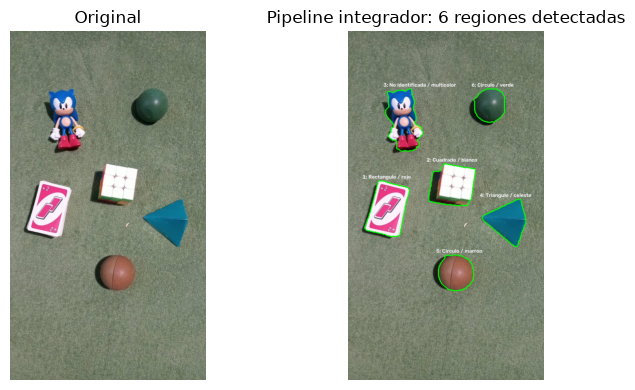

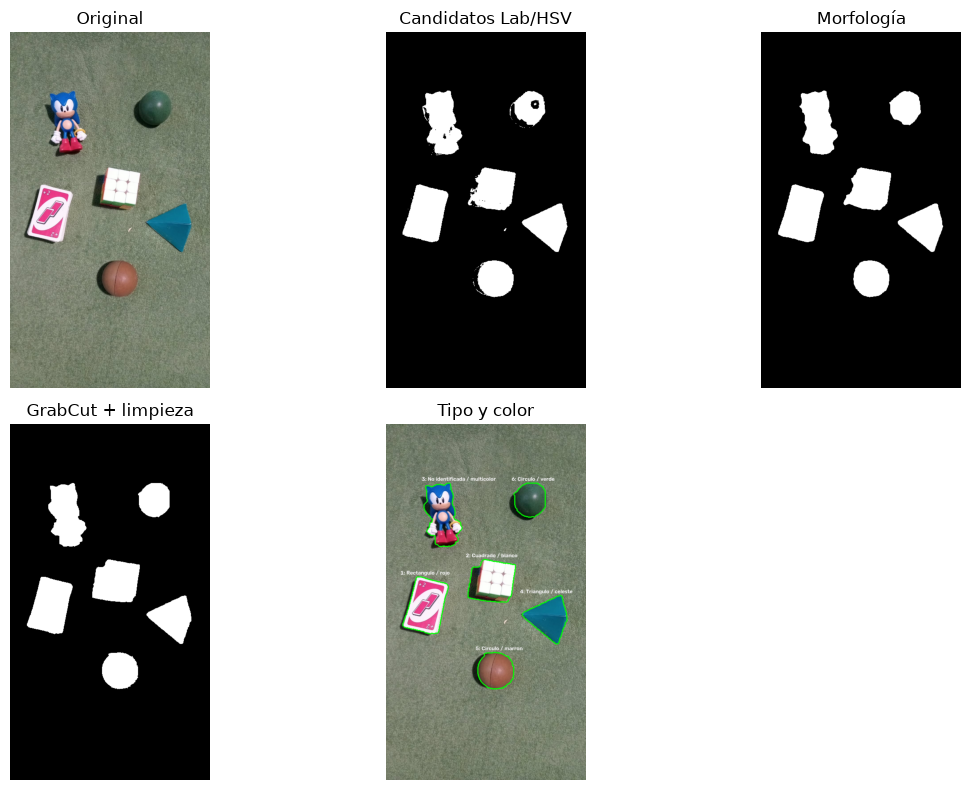

In [ ]:
img = imgs["01_cesped_6objetos.jpg"]
mascara_final, diagnostico = segmentar_fondo_color(img)
anotada, detecciones, total = pipeline_integrador(img)
print("Umbral cromático:",diagnostico["umbral_ab"])
for n,d in enumerate(detecciones,1):
    print(n,d["tipo"],d["color"],"bbox=",d["bbox"])
mostrar([img, anotada], ["Original", f"Pipeline integrador: {total} regiones detectadas"], cols=2)

# Etapas intermedias para explicar cómo se obtuvo el resultado.
mostrar([img,diagnostico["candidatos"],diagnostico["morfologia"],
         diagnostico["refinada"],anotada],
        ["Original","Candidatos Lab/HSV","Morfología","GrabCut + limpieza","Tipo y color"],cols=3)

## 8. Informe y conclusiones

**a) Metodología.** Trabajamos con Python, OpenCV (`cv2`), NumPy y Matplotlib en una notebook compatible con Google Colab. Partimos de diez fotografías propias de objetos reales, con fondos de césped, granito y papel, variaciones de luz, sombras y perspectiva. Estudiamos adquisición y formatos, cuantización y submuestreo, contraste, restauración, transformaciones geométricas, morfología, bordes, segmentación y color. Las secciones anteriores muestran los resultados de cada etapa y sus parámetros.

Reutilizamos la función `clasificar_forma` del TP1, incluida con su lógica original y con referencia al commit de origen, y conservamos su detector basado en Canny como línea de comparación. Evaluamos tres sistemas sobre las mismas imágenes: TP1, pipeline anterior con Otsu y pipeline integrador revisado con fondo Lab/HSV y GrabCut. La revisión modifica tanto la segmentación como la clasificación geométrica; por eso la mejora corresponde al sistema completo y no se atribuye exclusivamente a una sola técnica.

**b) Decisiones tomadas.**

- **Formato y adquisición:** se comparó la misma imagen decodificada en BMP, PNG y JPEG de calidad 90. Los tamaños obtenidos fueron 4218,80 KB, 3162,07 KB y 490,89 KB, respectivamente; JPEG dio un PSNR de 44,73 dB. Las fotografías originales son JPEG y se procesan sin recomprimir entre etapas. PNG y BMP conservan los píxeles decodificados, pero no recuperan información perdida antes de esta comparación.
- **Cuantización y submuestreo:** se redujo la escala de grises a cuatro niveles (0, 64, 128 y 192) y se aplicó reducción al 25 % seguida de ampliación por vecino más cercano, para observar pérdida de gradaciones y artefactos de muestreo.
- **Contraste:** se compararon ajuste lineal (`alpha=1,5`, `beta=10`), gamma y ecualización. En la foto oscura, gamma 0,5 elevó la media de gris de 66,87 a 126,94. Esa media indica un aclarado, no demuestra por sí sola mejor calidad ni recuperación de información. Para nombrar colores, el pipeline aplica gamma 0,5 a una copia BGR si la mediana global de V es menor que 100; la segmentación conserva la entrada original.
- **Ruido y filtros:** se agregó ruido sal y pimienta (2 %) y gaussiano (sigma 20), con semilla 7, y se compararon media, gaussiano y mediana con PSNR. Con ventana 3, la mediana fue la mejor para sal y pimienta (27,31 dB) y el gaussiano para ruido gaussiano (26,93 dB). La ventana 7 eliminó más detalle y produjo menor PSNR en la prueba de sal y pimienta.
- **Transformaciones:** se aplicaron rotación de 30°, escalado 0,5 y traslación (40,20). La homografía rectificó el mazo de cartas mediante cuatro esquinas manuales, a 210 × 300 px. Es una demostración sobre una figura plana, no una rectificación automática de las escenas ni de objetos 3D.
- **Morfología:** se compararon erosión, dilatación, apertura y cierre con rectángulos, elipses y cruces de 5 × 5 y 15 × 15. Las tablas del punto 4 muestran áreas y componentes; contar menos regiones no demuestra automáticamente una mejor segmentación. El pipeline trabaja con lado máximo de 800 px, apertura elíptica 5 × 5 y cierre 9 × 9 con dos iteraciones. Un cierre adicional 15 × 15 une únicamente grupos de fragmentos pequeños; tras GrabCut se utiliza cierre 5 × 5.
- **Bordes:** se compararon Sobel, Prewitt, Laplaciano y Canny (50,150), con suavizado gaussiano previo. Los mapas de gradiente se normalizan individualmente, por lo que sus porcentajes de píxeles fuertes no se interpretan como una medida común de precisión frente a Canny.
- **Segmentación:** Otsu se conserva como demostración y como parte del pipeline anterior. El revisado modela el borde del fondo con estadísticas robustas en Lab/HSV y combina distancia cromática, saturación y luminancia; aplica morfología y refinamiento local con GrabCut (tres iteraciones). Requiere fondo representativo en el borde y objetos separados dentro del encuadre.
- **Geometría y color:** se clasifican contornos con envolvente convexa, solidez, ocupación circular y rectángulo rotado, tolerando la rotación y rechazando formas ajenas a las cuatro clases. El color se calcula sobre el interior de cada máscara, con rangos HSV y reglas explícitas para blanco, negro, gris, marrón y multicolor. Estas reglas son heurísticas y no corrigen el balance de blancos.
- **Evaluación y reproducibilidad:** se usan 24 referencias manuales únicamente para evaluar. La localización exige IoU de cajas ≥0,50 y correspondencia uno a uno; forma y color se miden por separado. Se fijan la procedencia del TP1 y del conjunto, se verifica el SHA-256 del ZIP y se fija la semilla 7. Las referencias, las imágenes y las tablas quedan en esta notebook.

**c) Resultados.** Las secciones anteriores muestran el antes y el después de las técnicas. El pipeline revisado separa objetos que el anterior omitía o fragmentaba: en la primera fotografía localiza las seis regiones correspondientes a los seis objetos, reconoce las cinco formas geométricas previstas y rechaza la silueta de Sonic como «No identificada». La comparación directa del punto 7 permite observar este resultado junto a la imagen original; también se conservan las máscaras intermedias para explicar el proceso.

En el conjunto original se obtuvieron 24 localizaciones correctas, 19 aciertos de forma entre los 20 objetos de las cuatro clases y 23 aciertos de color entre las 24 localizaciones. La cadena completa de localización, forma y color acertó 18 de los 20 objetos geométricos. Persisten dos errores de clasificación: la pelota blanca se etiqueta como multicolor y el cubo con sombra como rectángulo. La pelota blanca también conserva un halo en la máscara: su IoU de caja es aproximadamente 0,502, apenas superior al umbral. Una localización válida no implica una máscara perfecta.

**d) Comparación de robustez.** Se comparan los tres sistemas sobre las mismas diez fotografías, usando las mismas referencias y el mismo criterio de localización. Las tablas siguientes muestran conteos reales, localizaciones correctas, falsas detecciones y omisiones, además de precisión, recall y F1. Se aplican también ruido gaussiano, sal y pimienta y reducción de brillo sin cambiar los parámetros. Los resultados se calculan en las celdas siguientes; una coincidencia aislada en el conteo total no se considera prueba de reconocimiento.

### Evaluación por objeto y criterios de comparación

Se anotan manualmente **24 objetos en diez fotografías**, con cajas aproximadas
de la silueta visible completa y sin sombras. No son máscaras de segmentación.
Las cajas se muestran para que puedan ser revisadas por el grupo.

Una localización correcta exige **IoU ≥0,50**, con emparejamiento uno a uno por IoU
descendente. Un fragmento, una sombra o una segunda detección del mismo objeto no
cuentan como otro objeto acertado. Se reportan TP, FP, FN, precisión, recall y F1.

**Convenciones previas:** triángulos, círculos, cartas rectangulares y cubos frontales
cuadrados; Sonic y el cubo con silueta 3D de la foto 09 quedan fuera de las cuatro formas.
La clasificación por forma se evalúa sobre referencias de esas cuatro clases, entre
localizaciones correctas. Rechazar las figuras fuera del vocabulario se informa aparte.
La cara frontal de un cubo puede verse cuadrilateral por perspectiva; esto se conserva como
una dificultad del sistema. La rectificación de la sección 4 no se utiliza en esta evaluación.

El color esperado es una etiqueta manual del objeto visible: se agrupan rojo y rosa en
la misma familia; objetos con varias zonas de color relevantes son multicolor. La pelota
blanca conserva su etiqueta material aunque la luz cálida la vuelva amarilla: esa diferencia
se contabiliza como error. El TP1 original no produce color y se indica como no disponible.

**Alcance:** estos datos se usaron para desarrollar y revisar el método. Los resultados
son descriptivos del conjunto de desarrollo, no una estimación de generalización ni un test independiente.

In [ ]:
# Cajas manuales aproximadas (x0,y0,x1,y1) en píxeles de las fotografías originales.
# Se anotó la silueta visible completa; se excluyen sombras y reflejos.
# No se utilizan para segmentar, elegir umbrales ni recortar entradas.
REFERENCIAS_PIXELES = {
 '01': [('sonic',(170,260,345,550),'No identificada','multicolor'),
        ('pelota_verde',(570,260,735,435),'Circulo','verde'),
        ('cartas',(65,680,290,950),'Rectangulo','rojo'),
        ('cubo',(365,605,590,815),'Cuadrado','blanco'),
        ('pelota_marron',(390,1020,585,1210),'Circulo','marron'),
        ('triangulo',(600,760,825,1000),'Triangulo','celeste')],
 '02': [('sonic',(155,335,345,630),'No identificada','multicolor'),
        ('pelota_verde',(550,300,715,470),'Circulo','verde'),
        ('cartas',(90,750,305,1025),'Rectangulo','rojo'),
        ('cubo',(380,655,595,860),'Cuadrado','blanco'),
        ('triangulo',(620,790,845,1030),'Triangulo','celeste')],
 '03': [('sonic',(450,1040,765,1250),'No identificada','multicolor'),
        ('pelota_verde',(535,760,715,950),'Circulo','verde'),
        ('cartas',(80,370,360,645),'Rectangulo','rojo'),
        ('cubo',(465,210,735,470),'Cuadrado','multicolor'),
        ('triangulo',(65,845,330,1120),'Triangulo','celeste')],
 '04': [('cubo',(290,280,715,710),'Cuadrado','blanco')],
 '05': [('pelota_blanca',(450,660,690,890),'Circulo','blanco')],
 '06': [('naranja',(195,695,710,1240),'Circulo','naranja')],
 '07': [('pelota_verde',(240,560,750,1080),'Circulo','verde')],
 '08': [('cubo',(170,560,475,895),'Cuadrado','multicolor')],
 '09': [('cubo_inclinado',(305,130,900,810),'No identificada','multicolor')],
 '10': [('manzana',(40,780,555,1320),'Circulo','rojo'),
        ('naranja',(585,855,1120,1390),'Circulo','naranja')]
}

def preparar_referencias(imgs):
    referencias = {}
    for nombre, imagen in imgs.items():
        h,w = imagen.shape[:2]
        referencias[nombre] = []
        for objeto,caja,tipo,color in REFERENCIAS_PIXELES[nombre[:2]]:
            x0,y0,x1,y1 = caja
            if not (0 <= x0 < x1 <= w and 0 <= y0 < y1 <= h):
                raise ValueError(f'Caja de referencia inválida: {nombre}/{objeto}')
            referencias[nombre].append({'objeto':objeto,'bbox':(x0,y0,x1-x0,y1-y0),
                                        'tipo':tipo,'color':color})
    return referencias

def iou_cajas(a,b):
    ax,ay,aw,ah=a; bx,by,bw,bh=b
    inter=max(0,min(ax+aw,bx+bw)-max(ax,bx))*max(0,min(ay+ah,by+bh)-max(ay,by))
    union=aw*ah+bw*bh-inter
    return inter/union if union else 0.0

def evaluar_detecciones(predicciones,referencias,umbral_iou=0.5,eval_color=True):
    """Emparejamiento uno a uno voraz por IoU descendente; no utiliza etiquetas."""
    candidatos = sorted([(iou_cajas(p['bbox'],g['bbox']),i,j)
                          for i,p in enumerate(predicciones) for j,g in enumerate(referencias)],
                         reverse=True)
    usados_p, usados_g, pares = set(),set(),[]
    for iou,i,j in candidatos:
        if iou >= umbral_iou and i not in usados_p and j not in usados_g:
            usados_p.add(i); usados_g.add(j); pares.append((i,j,iou))
    tp=len(pares); fp=len(predicciones)-tp; fn=len(referencias)-tp
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    conocidas=[(i,j,v) for i,j,v in pares if referencias[j]['tipo']!='No identificada']
    formas=sum(predicciones[i]['tipo']==referencias[j]['tipo'] for i,j,_ in conocidas)
    colores=sum(predicciones[i].get('color')==referencias[j]['color'] for i,j,_ in pares) if eval_color else 0
    conjuntas=sum(predicciones[i]['tipo']==referencias[j]['tipo'] and
                  predicciones[i].get('color')==referencias[j]['color'] for i,j,_ in conocidas) if eval_color else 0
    resultado={'reales':len(referencias),'predicciones':len(predicciones),'TP':tp,'FP':fp,'FN':fn,
               'precision':precision,'recall':recall,'F1':2*precision*recall/(precision+recall) if precision+recall else 0.,
               'formas_ok':formas,'formas_evaluadas':len(conocidas),
               'colores_ok':colores if eval_color else None,
               'colores_evaluados':tp if eval_color else 0,'forma_y_color_ok':conjuntas if eval_color else None}
    detalles=[]
    por_gt={j:(i,v) for i,j,v in pares}
    for j,g in enumerate(referencias):
        i,v=por_gt.get(j,(None,0.))
        p=predicciones[i] if i is not None else {}
        detalles.append({'objeto':g['objeto'],'estado':'localizado' if i is not None else 'omitido',
                         'iou':round(v,4),'tipo_real':g['tipo'],'tipo_predicho':p.get('tipo',''),
                         'color_real':g['color'],'color_predicho':p.get('color','') if eval_color else 'no disponible'})
    for i,p in enumerate(predicciones):
        if i not in usados_p:
            detalles.append({'objeto':'','estado':'falso positivo','iou':0.,'tipo_real':'',
                             'tipo_predicho':p['tipo'],'color_real':'','color_predicho':p.get('color','') if eval_color else 'no disponible'})
    return resultado,detalles

def agregar_metricas(filas):
    claves=['reales','predicciones','TP','FP','FN','formas_ok','formas_evaluadas','colores_evaluados']
    total={k:sum(f[k] for f in filas) for k in claves}
    total['colores_ok']=sum(f['colores_ok'] or 0 for f in filas)
    total['forma_y_color_ok']=sum(f['forma_y_color_ok'] or 0 for f in filas)
    if total['colores_evaluados']==0:
        total['colores_ok']=None
        total['forma_y_color_ok']=None
    total['precision']=total['TP']/max(1,total['TP']+total['FP'])
    total['recall']=total['TP']/max(1,total['TP']+total['FN'])
    p,r=total['precision'],total['recall']
    total['F1']=2*p*r/(p+r) if p+r else 0.
    return total

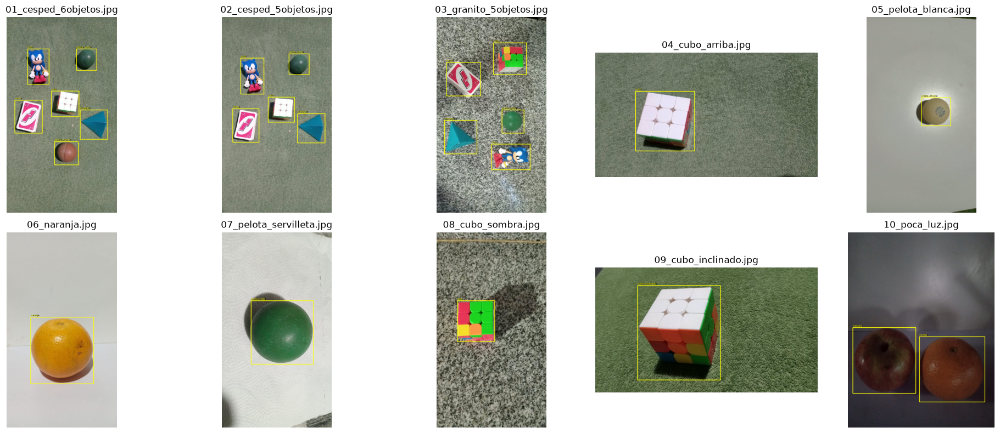

In [ ]:
referencias = preparar_referencias(imgs)
vistas=[]
for nombre,im in imgs.items():
    vista=im.copy()
    for g in referencias[nombre]:
        x,y,w,h=g["bbox"]
        cv2.rectangle(vista,(x,y),(x+w,y+h),(0,255,255),3)
        cv2.putText(vista,g["objeto"],(x,max(25,y-8)),cv2.FONT_HERSHEY_SIMPLEX,.65,(0,0,0),3)
        cv2.putText(vista,g["objeto"],(x,max(25,y-8)),cv2.FONT_HERSHEY_SIMPLEX,.65,(0,255,255),1)
    vistas.append(vista)
mostrar(vistas,list(imgs),cols=5)

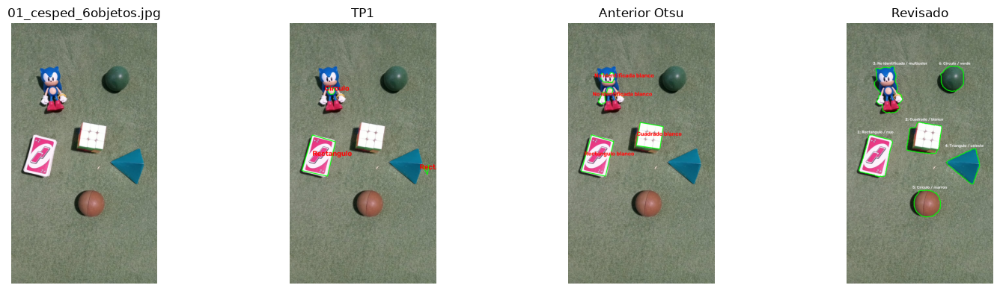

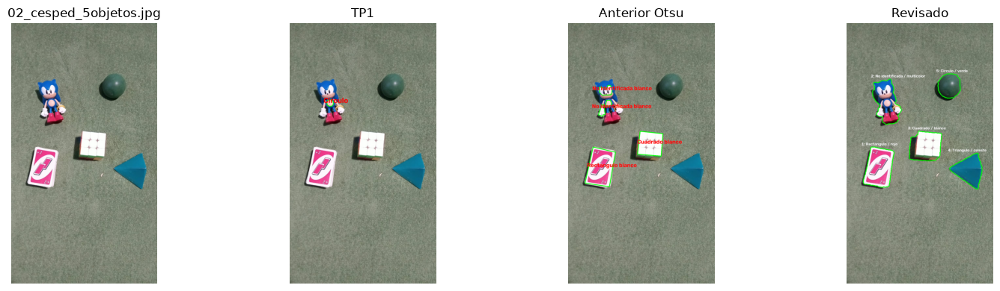

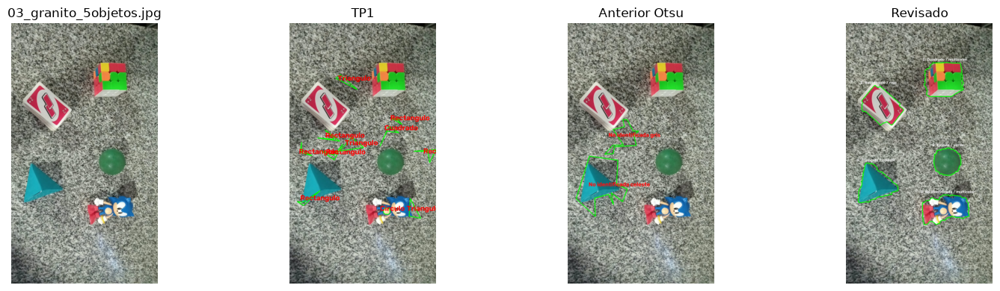

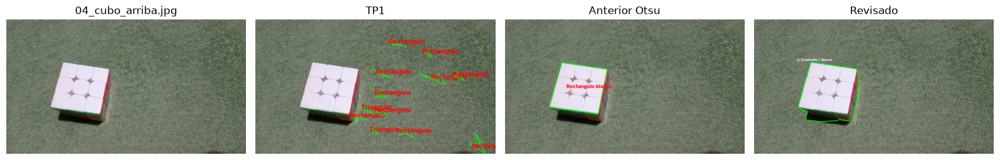

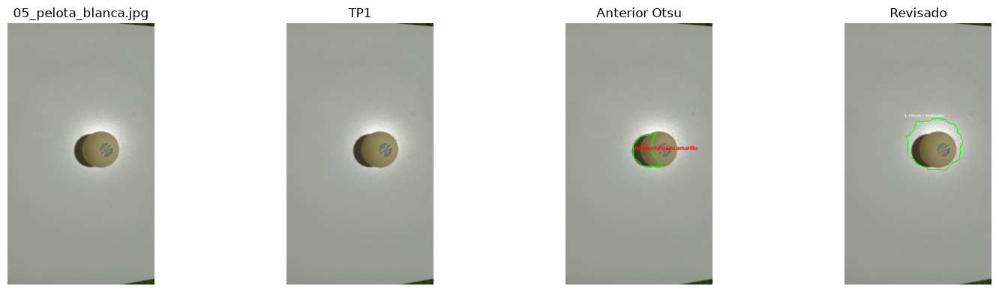

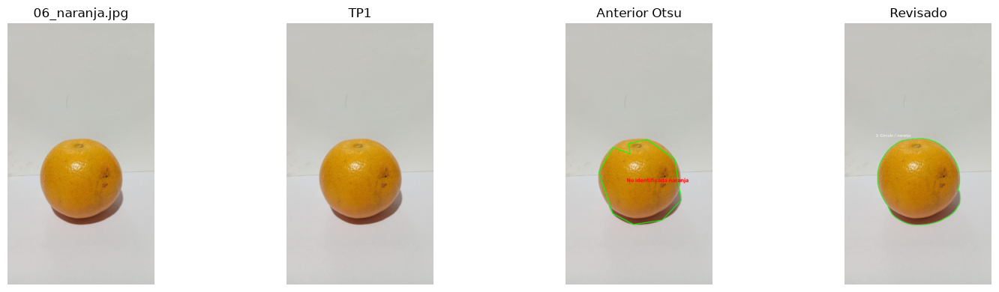

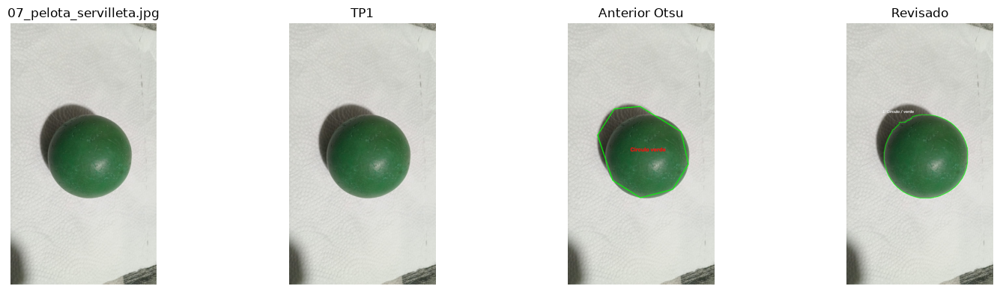

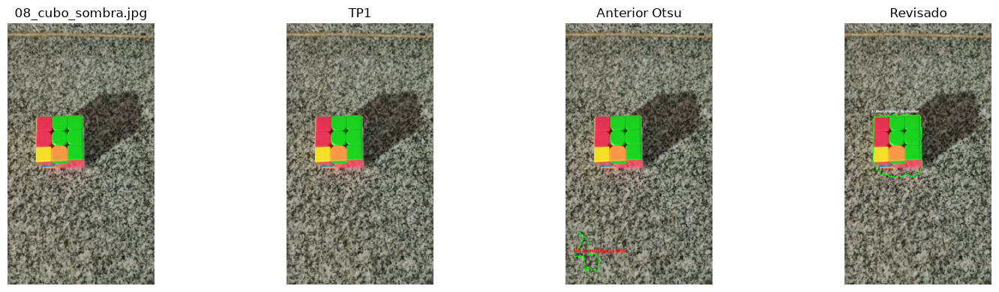

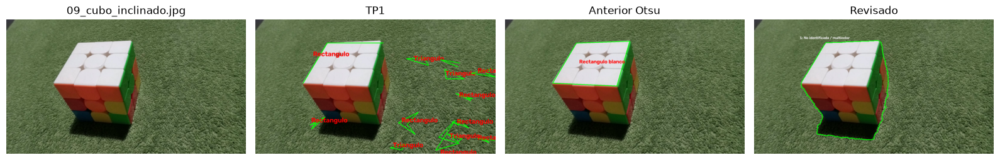

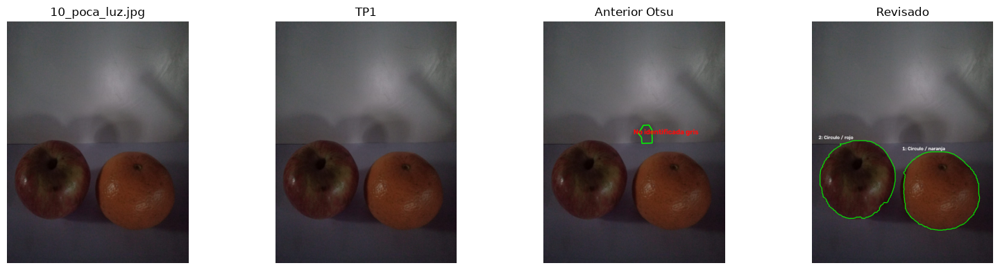

Sistema         Imagen                     Real Pred  TP  FP  FN
TP1             01_cesped_6objetos.jpg        6   15   2  13   4
Anterior Otsu   01_cesped_6objetos.jpg        6    4   2   2   4
Revisado        01_cesped_6objetos.jpg        6    6   6   0   0
TP1             02_cesped_5objetos.jpg        5    9   1   8   4
Anterior Otsu   02_cesped_5objetos.jpg        5    4   2   2   3
Revisado        02_cesped_5objetos.jpg        5    5   5   0   0
TP1             03_granito_5objetos.jpg       5  160   0 160   5
Anterior Otsu   03_granito_5objetos.jpg       5    2   1   1   4
Revisado        03_granito_5objetos.jpg       5    5   5   0   0
TP1             04_cubo_arriba.jpg            1   90   0  90   1
Anterior Otsu   04_cubo_arriba.jpg            1    1   1   0   0
Revisado        04_cubo_arriba.jpg            1    1   1   0   0
TP1             05_pelota_blanca.jpg          1    0   0   0   1
Anterior Otsu   05_pelota_blanca.jpg          1    1   0   1   1
Revisado        05_pelota

|Sistema|TP|FP|FN|Precisión|Recall|F1|Forma correcta/localizadas evaluables|Color correcto/localizadas|
|---|---:|---:|---:|---:|---:|---:|---:|---:|
|TP1|5|374|19|0.013|0.208|0.025|1/4|No disponible|
|Anterior Otsu|8|9|16|0.471|0.333|0.390|5/8|6/8|
|Revisado|24|0|0|1.000|1.000|1.000|19/20|23/24|


In [ ]:
predicciones = {s:{} for s in ("TP1","Anterior Otsu","Revisado")}
filas, detalles = [], []
for nombre,im in imgs.items():
    tp1,dp1=clasificar_formas(im)
    ant,da,_=pipeline_anterior(im)
    rev,dr,_=pipeline_integrador(im)
    for sistema,det in [("TP1",dp1),("Anterior Otsu",da),("Revisado",dr)]:
        predicciones[sistema][nombre]=det
        met,detalles_im=evaluar_detecciones(det,referencias[nombre],eval_color=sistema!="TP1")
        filas.append({"sistema":sistema,"imagen":nombre,**met})
        detalles.extend({"sistema":sistema,"imagen":nombre,**d} for d in detalles_im)
    mostrar([im,tp1,ant,rev],[nombre,"TP1","Anterior Otsu","Revisado"],cols=4)

print(f"{'Sistema':<15} {'Imagen':<26} {'Real':>4} {'Pred':>4} {'TP':>3} {'FP':>3} {'FN':>3}")
for f in filas:
    print(f"{f['sistema']:<15} {f['imagen']:<26} {f['reales']:>4} {f['predicciones']:>4} {f['TP']:>3} {f['FP']:>3} {f['FN']:>3}")
agregados={s:agregar_metricas([f for f in filas if f["sistema"]==s]) for s in predicciones}
tabla_resumen="|Sistema|TP|FP|FN|Precisión|Recall|F1|Forma correcta/localizadas evaluables|Color correcto/localizadas|\n|---|---:|---:|---:|---:|---:|---:|---:|---:|\n"
for s,a in agregados.items():
    color=f"{a['colores_ok']}/{a['colores_evaluados']}" if s!="TP1" else "No disponible"
    tabla_resumen+=f"|{s}|{a['TP']}|{a['FP']}|{a['FN']}|{a['precision']:.3f}|{a['recall']:.3f}|{a['F1']:.3f}|{a['formas_ok']}/{a['formas_evaluadas']}|{color}|\n"
display(Markdown(tabla_resumen))

In [ ]:
print("\nRechazo de objetos fuera de las cuatro clases (entre localizados):")
for s in predicciones:
    fuera=[d for d in detalles if d["sistema"]==s and d["estado"]=="localizado" and d["tipo_real"]=="No identificada"]
    print(s, sum(d["tipo_predicho"]=="No identificada" for d in fuera),"/",len(fuera))
print("\nErrores o rechazos del sistema revisado:")
for d in detalles:
    if d["sistema"]=="Revisado" and (d["estado"]!="localizado" or d["tipo_real"]!=d["tipo_predicho"] or d["color_real"]!=d["color_predicho"]):
        print(d["imagen"],d["objeto"],d["estado"],"IoU",d["iou"],
              "| forma",d["tipo_real"],"->",d["tipo_predicho"],"| color",d["color_real"],"->",d["color_predicho"])


Rechazo de objetos fuera de las cuatro clases (entre localizados):
TP1 1 / 1
Anterior Otsu 0 / 0
Revisado 4 / 4

Errores o rechazos del sistema revisado:
05_pelota_blanca.jpg pelota_blanca localizado IoU 0.502 | forma Circulo -> Circulo | color blanco -> multicolor
08_cubo_sombra.jpg cubo localizado IoU 0.8561 | forma Cuadrado -> Rectangulo | color multicolor -> multicolor


### Robustez ante perturbaciones controladas

Se aplican ruido gaussiano (σ=10), ruido sal y pimienta (1%) y reducción de brillo
(factor 0,6) a las mismas diez imágenes. Las cajas de referencia no cambian porque
estas perturbaciones no cambian la geometría. Se mantienen todos los parámetros.
Esto complementa las distintas condiciones de las fotos; no reemplaza un conjunto de prueba nuevo.

In [ ]:
robustez=[]
for condicion in ("original","gaussiano_sigma10","sal_pimienta_1pct","brillo_0.6"):
    for sistema in ("TP1","Anterior Otsu","Revisado"):
        met=[]
        for nombre,im in imgs.items():
            if condicion=="original":
                ds=predicciones[sistema][nombre]
            else:
                entrada=(ruido_gaussiano(im,10) if condicion=="gaussiano_sigma10" else
                         ruido_sal_pimienta(im,.01) if condicion=="sal_pimienta_1pct" else
                         np.clip(im.astype(np.float32)*.6,0,255).astype(np.uint8))
                ds=(clasificar_formas(entrada)[1] if sistema=="TP1" else
                    pipeline_anterior(entrada)[1] if sistema=="Anterior Otsu" else
                    pipeline_integrador(entrada)[1])
            met.append(evaluar_detecciones(ds,referencias[nombre],eval_color=sistema!="TP1")[0])
        a=agregar_metricas(met)
        robustez.append({"condicion":condicion,"sistema":sistema,**a})
        print(f"{condicion:<22} {sistema:<14} TP={a['TP']:2d} FP={a['FP']:3d} FN={a['FN']:2d} F1={a['F1']:.3f}")

original               TP1            TP= 5 FP=374 FN=19 F1=0.025
original               Anterior Otsu  TP= 8 FP=  9 FN=16 F1=0.390
original               Revisado       TP=24 FP=  0 FN= 0 F1=1.000


gaussiano_sigma10      TP1            TP= 4 FP=443 FN=20 F1=0.017


gaussiano_sigma10      Anterior Otsu  TP= 7 FP=  9 FN=17 F1=0.350


gaussiano_sigma10      Revisado       TP=23 FP=  3 FN= 1 F1=0.920


sal_pimienta_1pct      TP1            TP= 4 FP=477 FN=20 F1=0.016


sal_pimienta_1pct      Anterior Otsu  TP= 8 FP=  9 FN=16 F1=0.390


sal_pimienta_1pct      Revisado       TP=24 FP=  0 FN= 0 F1=1.000


brillo_0.6             TP1            TP= 3 FP= 93 FN=21 F1=0.050


brillo_0.6             Anterior Otsu  TP= 8 FP=  9 FN=16 F1=0.390


brillo_0.6             Revisado       TP=23 FP=  1 FN= 1 F1=0.958


**e) Conclusiones.**

Aprendimos que el clasificador de figuras ideales del TP1 necesita una segmentación adecuada para trabajar con fotografías reales. Incorporar información de color y un refinamiento de máscara permitió reducir las falsas detecciones y recuperar objetos que Otsu en gris no separaba. El rechazo de formas fuera del vocabulario evita asignar una figura geométrica a cualquier silueta.

El balance cuantitativo y las limitaciones se generan a continuación a partir de la ejecución, para mantener el informe vinculado a los resultados. Las pruebas corresponden al conjunto de desarrollo: no permiten afirmar que el sistema generalice con el mismo desempeño a nuevas fotografías.

In [ ]:
nuevo=agregados["Revisado"]; viejo=agregados["Anterior Otsu"]; base=agregados["TP1"]
total_conocidas=sum(g["tipo"]!="No identificada" for gs in referencias.values() for g in gs)
texto=f"""**Balance cuantitativo del conjunto de desarrollo, IoU ≥0,50.**
El TP1 localiza {base['TP']} de {base['reales']} objetos, con {base['FP']} falsos positivos
y F1={base['F1']:.3f}. El pipeline anterior localiza {viejo['TP']}, con {viejo['FP']} falsos
positivos y F1={viejo['F1']:.3f}. El revisado localiza {nuevo['TP']}, con {nuevo['FP']} falsos
positivos, {nuevo['FN']} omisiones y F1={nuevo['F1']:.3f}.

Entre los objetos correctamente localizados y pertenecientes a las cuatro clases,
el revisado clasifica bien la forma en {nuevo['formas_ok']}/{nuevo['formas_evaluadas']}.
El color coincide con la referencia en {nuevo['colores_ok']}/{nuevo['colores_evaluados']}
localizaciones. La cadena completa localización+forma+color acierta
{nuevo['forma_y_color_ok']}/{total_conocidas} objetos de las cuatro clases, incluyendo
las omisiones en el denominador. Son métricas diferentes y no deben intercambiarse.

**Robustez observada.** Con ruido gaussiano, la cadena completa acierta
{next(r['forma_y_color_ok'] for r in robustez if r['sistema']=='Revisado' and r['condicion']=='gaussiano_sigma10')}/{total_conocidas};
con sal y pimienta,
{next(r['forma_y_color_ok'] for r in robustez if r['sistema']=='Revisado' and r['condicion']=='sal_pimienta_1pct')}/{total_conocidas};
y con brillo reducido al 60%,
{next(r['forma_y_color_ok'] for r in robustez if r['sistema']=='Revisado' and r['condicion']=='brillo_0.6')}/{total_conocidas}.
La localización resiste mejor que el reconocimiento conjunto, especialmente ante la reducción de iluminación.

**Limitaciones y próximos pasos.** Las cajas manuales son aproximadas; reflejos, sombras
y perspectiva pueden alterar la máscara, la forma y el color. El modelo supone fondo
representativo en el borde, descarta candidatos pegados al encuadre y no separa objetos
en contacto. Los umbrales de color no realizan constancia de color: una pelota blanca
con iluminación cálida o una fruta oscura pueden recibir otra etiqueta. La prueba con
perturbaciones muestra sensibilidad dentro de este conjunto; para estimar generalización
hacen falta fotos nuevas, anotadas antes de evaluar y no usadas para ajustar parámetros.

El aprendizaje principal es que la calidad de la segmentación condiciona las etapas
posteriores y que contar regiones no equivale a reconocer objetos. Se mantiene una
política de rechazo para figuras que no corresponden a las cuatro formas previstas.
"""
display(Markdown(texto))

**Balance cuantitativo del conjunto de desarrollo, IoU ≥0,50.**
El TP1 localiza 5 de 24 objetos, con 374 falsos positivos
y F1=0.025. El pipeline anterior localiza 8, con 9 falsos
positivos y F1=0.390. El revisado localiza 24, con 0 falsos
positivos, 0 omisiones y F1=1.000.

Entre los objetos correctamente localizados y pertenecientes a las cuatro clases,
el revisado clasifica bien la forma en 19/20.
El color coincide con la referencia en 23/24
localizaciones. La cadena completa localización+forma+color acierta
18/20 objetos de las cuatro clases, incluyendo
las omisiones en el denominador. Son métricas diferentes y no deben intercambiarse.

**Robustez observada.** Con ruido gaussiano, la cadena completa acierta
17/20;
con sal y pimienta,
18/20;
y con brillo reducido al 60%,
12/20.
La localización resiste mejor que el reconocimiento conjunto, especialmente ante la reducción de iluminación.

**Limitaciones y próximos pasos.** Las cajas manuales son aproximadas; reflejos, sombras
y perspectiva pueden alterar la máscara, la forma y el color. El modelo supone fondo
representativo en el borde, descarta candidatos pegados al encuadre y no separa objetos
en contacto. Los umbrales de color no realizan constancia de color: una pelota blanca
con iluminación cálida o una fruta oscura pueden recibir otra etiqueta. La prueba con
perturbaciones muestra sensibilidad dentro de este conjunto; para estimar generalización
hacen falta fotos nuevas, anotadas antes de evaluar y no usadas para ajustar parámetros.

El aprendizaje principal es que la calidad de la segmentación condiciona las etapas
posteriores y que contar regiones no equivale a reconocer objetos. Se mantiene una
política de rechazo para figuras que no corresponden a las cuatro formas previstas.
